In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/sourish05/cleaned-fraud-data/cleaned_fraud_data.csv


In [2]:
# Cell 1.1 — Setup and imports
import os, time, gc, json, warnings
import numpy as np
import pandas as pd
from datetime import datetime

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (roc_auc_score, average_precision_score,
                              precision_score, recall_score, f1_score,
                              precision_recall_curve, roc_curve,
                              classification_report, confusion_matrix)
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras import layers, Model, callbacks, optimizers, regularizers
from tensorflow.keras.metrics import AUC

import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import lightgbm as lgb

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

DATA_PATH = "/kaggle/input/datasets/sourish05/cleaned-fraud-data/cleaned_fraud_data.csv"
MODEL_DIR = "/kaggle/working/models_v3"
FIG_DIR   = "/kaggle/working/figures_v3"
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (10, 5),
                     "axes.titlesize": 13,
                     "axes.titleweight": "bold"})

print(f"TensorFlow: {tf.__version__}")
print(f"LightGBM  : {lgb.__version__}")
print("Setup ready.")

TensorFlow: 2.20.0
LightGBM  : 4.6.0
Setup ready.


In [3]:
# Cell 1.2 — Load and diagnose
df = pd.read_csv(DATA_PATH, low_memory=False)
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
df = df.dropna(subset=["timestamp"]).sort_values("timestamp").reset_index(drop=True)

print("=" * 70)
print("DATASET DIAGNOSIS")
print("=" * 70)
print(f"Rows           : {len(df):,}")
print(f"Columns        : {df.shape[1]}")
print(f"Memory         : {df.memory_usage(deep=True).sum() / 1e6:.2f} MB")
print(f"Fraud rate     : {df['fraud_label'].mean():.4f}")
print(f"Fraud count    : {int(df['fraud_label'].sum()):,}")
print(f"Time range     : {df['timestamp'].min()} -> {df['timestamp'].max()}")
print(f"Days span      : {(df['timestamp'].max() - df['timestamp'].min()).days}")
print(f"Unique cust    : {df['customer_id'].nunique():,}")
print(f"Missing cells  : {int(df.isna().sum().sum()):,}")
print(f"Duplicate rows : {int(df.duplicated().sum()):,}")
print(f"\nAll 28 columns:")
for i, c in enumerate(df.columns, 1):
    print(f"  {i:2d}. {c:30s} {str(df[c].dtype):15s} unique={df[c].nunique():>8,}")

DATASET DIAGNOSIS
Rows           : 502,316
Columns        : 28
Memory         : 355.70 MB
Fraud rate     : 0.0500
Fraud count    : 25,121
Time range     : 2023-01-01 00:04:00 -> 2024-12-30 23:50:00
Days span      : 729
Unique cust    : 50,978
Missing cells  : 0
Duplicate rows : 0

All 28 columns:
   1. transaction_id                 object          unique= 502,316
   2. customer_id                    object          unique=  50,978
   3. timestamp                      datetime64[ns]  unique= 392,070
   4. amount                         float64         unique=  21,784
   5. merchant                       object          unique=      31
   6. merchant_category              object          unique=      13
   7. card_type                      object          unique=       6
   8. card_last4                     float64         unique=   8,999
   9. country                        object          unique=      15
  10. city                           object          unique=      16
  11. device

In [4]:
# Cell 1.3 — Check per-customer transaction counts
txns_per_cust = df.groupby("customer_id").size()

print("TRANSACTIONS PER CUSTOMER")
print(f"  Mean      : {txns_per_cust.mean():.2f}")
print(f"  Median    : {txns_per_cust.median():.0f}")
print(f"  Max       : {txns_per_cust.max()}")
print(f"  Min       : {txns_per_cust.min()}")

for q in [0.5, 0.75, 0.90, 0.95, 0.99]:
    print(f"  {int(q*100)}th pct : {txns_per_cust.quantile(q):.0f}")

# This informs whether a GRU sequence model is viable
n_ge_10 = (txns_per_cust >= 10).sum()
n_ge_5  = (txns_per_cust >= 5).sum()
print(f"\nCustomers with >=5 txns : {n_ge_5:,} ({n_ge_5/len(txns_per_cust)*100:.1f}%)")
print(f"Customers with >=10 txns: {n_ge_10:,} ({n_ge_10/len(txns_per_cust)*100:.1f}%)")

if n_ge_10 / len(txns_per_cust) > 0.20:
    print("\n[OK] Sequence model (GRU) is VIABLE — enough customers have history")
    SEQUENCE_VIABLE = True
else:
    print("\n[WARNING] Sequence model may not have enough data per customer")
    SEQUENCE_VIABLE = False

TRANSACTIONS PER CUSTOMER
  Mean      : 9.85
  Median    : 10
  Max       : 5029
  Min       : 1
  50th pct : 10
  75th pct : 12
  90th pct : 14
  95th pct : 15
  99th pct : 18

Customers with >=5 txns : 48,372 (94.9%)
Customers with >=10 txns: 26,646 (52.3%)

[OK] Sequence model (GRU) is VIABLE — enough customers have history


In [5]:
# Cell 1.4 — Leakage check: feature means must be close between classes
print("LEAKAGE CHECK — feature means by class")
print(f"{'feature':30s} {'normal':>12s} {'fraud':>12s} {'ratio':>8s}")
print("-" * 70)

num_cols = df.select_dtypes(include=np.number).columns.tolist()
num_cols = [c for c in num_cols if c != "fraud_label"]

for col in num_cols:
    n = df.loc[df.fraud_label == 0, col].mean()
    f = df.loc[df.fraud_label == 1, col].mean()
    ratio = f / (n + 1e-9)
    flag = " *** LEAK" if (ratio > 1.5 or ratio < 0.7) else ""
    print(f"{col:30s} {n:>12.4f} {f:>12.4f} {ratio:>8.3f}{flag}")

print("\nIf any *** LEAK rows exist, the dataset has distributional leakage.")
print("Ratio should be between 0.7 and 1.5 for a fair fraud problem.")

LEAKAGE CHECK — feature means by class
feature                              normal        fraud    ratio
----------------------------------------------------------------------
amount                              49.9270     152.2457    3.049 *** LEAK
card_last4                        5504.0064    5493.2469    0.998
is_international                     0.1528       0.6956    4.552 *** LEAK
txn_count_10min                      0.9998       4.8616    4.862 *** LEAK
txn_count_24h                        2.9966       7.5887    2.532 *** LEAK
avg_amount_30d                      38.9818      38.9109    0.998
account_age_days                  2494.2128     320.6921    0.129 *** LEAK
credit_limit                    359668.6893  360674.3368    1.003
hour_of_day                         11.4818      11.5149    1.003
is_night                             0.2047       0.2000    0.977
distance_from_home_km               19.4238      80.9090    4.165 *** LEAK
year                              2023.4736 

In [6]:
# Cell 2.1 — Time-aware split FIRST (prevents all leakage)
n = len(df)
train_end = int(n * 0.70)
val_end   = int(n * 0.85)

train_df = df.iloc[:train_end].copy()
val_df   = df.iloc[train_end:val_end].copy()
test_df  = df.iloc[val_end:].copy()

print("SPLIT")
print(f"Train: {len(train_df):,} | fraud={train_df.fraud_label.mean()*100:.2f}%")
print(f"Val  : {len(val_df):,} | fraud={val_df.fraud_label.mean()*100:.2f}%")
print(f"Test : {len(test_df):,} | fraud={test_df.fraud_label.mean()*100:.2f}%")

SPLIT
Train: 351,621 | fraud=4.77%
Val  : 75,347 | fraud=4.75%
Test : 75,348 | fraud=6.31%


In [51]:
# Cell 2.2 (Fixed) — Customer fingerprint with strict train-only history
# Drop any fingerprint columns that may exist from a previous run
FP_COLS = [
    "cust_txn_count", "cust_amount_mean", "cust_amount_std",
    "cust_amount_max", "cust_amount_min", "cust_n_international",
    "cust_n_night", "cust_dist_mean", "cust_dist_max",
    "cust_age_days", "cust_credit_limit", "cust_intl_ratio",
    "cust_night_ratio", "cust_amount_cv", "has_train_history",
]
for d_name in ["train_df", "val_df", "test_df"]:
    d = globals()[d_name]
    drop_existing = [c for c in FP_COLS if c in d.columns]
    if drop_existing:
        globals()[d_name] = d.drop(columns=drop_existing)
        print(f"Dropped existing fingerprint cols from {d_name}: {drop_existing}")

train_df = globals()["train_df"]
val_df   = globals()["val_df"]
test_df  = globals()["test_df"]

def build_customer_fingerprint(train_df):
    fp = train_df.groupby("customer_id").agg(
        cust_txn_count=("transaction_id", "count"),
        cust_amount_mean=("amount", "mean"),
        cust_amount_std=("amount", "std"),
        cust_amount_max=("amount", "max"),
        cust_amount_min=("amount", "min"),
        cust_n_international=("is_international", "sum"),
        cust_n_night=("is_night", "sum"),
        cust_dist_mean=("distance_from_home_km", "mean"),
        cust_dist_max=("distance_from_home_km", "max"),
        cust_age_days=("account_age_days", "first"),
        cust_credit_limit=("credit_limit", "first"),
    ).reset_index()
    fp["cust_amount_std"] = fp["cust_amount_std"].fillna(0)
    fp["cust_intl_ratio"]  = fp["cust_n_international"] / (fp["cust_txn_count"] + 1e-6)
    fp["cust_night_ratio"] = fp["cust_n_night"] / (fp["cust_txn_count"] + 1e-6)
    fp["cust_amount_cv"]   = fp["cust_amount_std"] / (fp["cust_amount_mean"] + 1e-6)
    return fp

customer_fp = build_customer_fingerprint(train_df)
print(f"Customer fingerprints: {customer_fp.shape}")

train_df = train_df.merge(customer_fp, on="customer_id", how="left")
val_df   = val_df.merge(customer_fp, on="customer_id", how="left")
test_df  = test_df.merge(customer_fp, on="customer_id", how="left")

# Add the has_train_history flag
for d_name in ["train_df", "val_df", "test_df"]:
    d = globals()[d_name]
    d["has_train_history"] = d["cust_txn_count"].notna().astype(int)
    globals()[d_name] = d

val_unseen  = (val_df["has_train_history"] == 0).mean()
test_unseen = (test_df["has_train_history"] == 0).mean()

print(f"\nFingerprint merge complete:")
print(f"  Train shape: {train_df.shape}")
print(f"  Val shape  : {val_df.shape}")
print(f"  Test shape : {test_df.shape}")
print(f"  Val customers with no train history : {val_unseen*100:.1f}%")
print(f"  Test customers with no train history: {test_unseen*100:.1f}%")
print(f"\nSample fingerprint columns present:")
print([c for c in train_df.columns if c.startswith("cust_") or c == "has_train_history"])

Customer fingerprints: (50650, 15)

Fingerprint merge complete:
  Train shape: (351621, 94)
  Val shape  : (75347, 94)
  Test shape : (75348, 94)
  Val customers with no train history : 0.3%
  Test customers with no train history: 0.3%

Sample fingerprint columns present:
['cust_txn_count_x', 'cust_amount_mean_x', 'cust_amount_std_x', 'cust_amount_max_x', 'cust_amount_min_x', 'cust_n_international_x', 'cust_n_night_x', 'cust_dist_mean_x', 'cust_dist_max_x', 'cust_age_days_x', 'cust_credit_limit_x', 'cust_intl_ratio_x', 'cust_night_ratio_x', 'cust_amount_cv_x', 'cust_txn_count_y', 'cust_amount_mean_y', 'cust_amount_std_y', 'cust_amount_max_y', 'cust_amount_min_y', 'cust_n_international_y', 'cust_n_night_y', 'cust_dist_mean_y', 'cust_dist_max_y', 'cust_age_days_y', 'cust_credit_limit_y', 'cust_intl_ratio_y', 'cust_night_ratio_y', 'cust_amount_cv_y', 'cust_txn_count', 'cust_amount_mean', 'cust_amount_std', 'cust_amount_max', 'cust_amount_min', 'cust_n_international', 'cust_n_night', 'cust

In [52]:
# Cell 2.3 (Replacement) — Deviation features (keep NaN for unseen customers)
def add_deviation_features(d):
    d = d.copy()
    d["amount_dev_from_cust"]   = (d["amount"] - d["cust_amount_mean"]) / (d["cust_amount_std"] + 1e-3)
    d["amount_vs_cust_max"]     = d["amount"] / (d["cust_amount_max"] + 1e-3)
    d["distance_dev_from_cust"] = (d["distance_from_home_km"] - d["cust_dist_mean"]) / (d["cust_dist_max"] + 1e-3)
    d["intl_vs_cust_norm"]      = d["is_international"] - d["cust_intl_ratio"]
    d["night_vs_cust_norm"]     = d["is_night"] - d["cust_night_ratio"]
    d["velocity_vs_cust"]       = d["txn_count_10min"] / (d["cust_txn_count"] / 730 + 1e-3)
    return d

train_df = add_deviation_features(train_df)
val_df   = add_deviation_features(val_df)
test_df  = add_deviation_features(test_df)

print("Deviation features added.")
print(f"Shape: {train_df.shape}")

Deviation features added.
Shape: (351621, 94)


In [53]:
# Cell 2.4 (Replacement) — Burst features from strictly EARLIER transactions only
def add_past_burst_features(train_df, val_df, test_df):
    def _per_split(d, history=None):
        d = d.copy()
        d["_orig_idx"] = np.arange(len(d))

        if history is not None:
            combined = pd.concat([
                history[["customer_id", "timestamp"]].assign(_split="hist"),
                d[["customer_id", "timestamp", "_orig_idx"]].assign(_split="cur"),
            ], ignore_index=True)
        else:
            combined = d[["customer_id", "timestamp", "_orig_idx"]].assign(_split="cur")

        combined = combined.sort_values(["customer_id", "timestamp"]).reset_index(drop=True)
        result_30 = np.zeros(len(combined), dtype=np.int32)
        result_2h = np.zeros(len(combined), dtype=np.int32)

        for cust, group in combined.groupby("customer_id", sort=False):
            times = group["timestamp"].values.astype("datetime64[s]").astype(np.int64)
            gidx = group.index.values
            for i in range(len(times)):
                t = times[i]
                earlier_mask = times[:i] < t
                result_30[gidx[i]] = ((earlier_mask) & (times[:i] >= t - 1800)).sum()
                result_2h[gidx[i]] = ((earlier_mask) & (times[:i] >= t - 7200)).sum()

        combined["burst_30min"] = result_30
        combined["burst_2h"] = result_2h
        cur = combined[combined["_split"] == "cur"].sort_values("_orig_idx").reset_index(drop=True)

        d["burst_30min"] = cur["burst_30min"].values
        d["burst_2h"]    = cur["burst_2h"].values
        d["is_burst_30min"] = (d["burst_30min"] >= 3).astype(int)
        d["is_burst_2h"]    = (d["burst_2h"] >= 5).astype(int)
        return d.drop(columns=["_orig_idx"])

    train_df = _per_split(train_df, history=None)
    val_df   = _per_split(val_df, history=train_df[["customer_id", "timestamp"]])

    history_for_test = pd.concat([
        train_df[["customer_id", "timestamp"]],
        val_df[["customer_id", "timestamp"]],
    ], ignore_index=True)
    test_df = _per_split(test_df, history=history_for_test)

    return train_df, val_df, test_df

t0 = time.time()
train_df, val_df, test_df = add_past_burst_features(train_df, val_df, test_df)
print(f"Past-only burst features added in {time.time()-t0:.1f}s")

for col in ["burst_30min", "burst_2h"]:
    n = train_df.loc[train_df.fraud_label == 0, col].mean()
    f = train_df.loc[train_df.fraud_label == 1, col].mean()
    print(f"  {col:15s} normal={n:.2f} fraud={f:.2f} ratio={f/(n+1e-9):.2f}")

Past-only burst features added in 24.2s
  burst_30min     normal=0.00 fraud=0.00 ratio=1.13
  burst_2h        normal=0.01 fraud=0.01 ratio=0.93


In [54]:
# Cell 2.5 — Frequency encoding (fit on train only)
FREQ_COLS = ["merchant", "merchant_category", "country",
             "city", "device_type", "channel", "card_type"]

freq_maps = {c: train_df[c].astype(str).value_counts(normalize=True)
             for c in FREQ_COLS}

def add_freq_features(d):
    d = d.copy()
    for c in FREQ_COLS:
        d[f"{c}_freq"] = d[c].astype(str).map(freq_maps[c]).fillna(0.0)
    return d

train_df = add_freq_features(train_df)
val_df   = add_freq_features(val_df)
test_df  = add_freq_features(test_df)

print("Frequency features added.")

Frequency features added.


In [55]:
# Cell 2.6 — Domain-informed risk flags
HIGH_RISK_CATS = {"Crypto", "Gambling", "Adult", "Wire Transfer", "Gift Cards"}
HIGH_RISK_COUNTRIES = {"KP", "IR", "RU", "NG", "PK"}

def add_risk_flags(d):
    d = d.copy()
    d["is_high_risk_cat"] = d["merchant_category"].isin(HIGH_RISK_CATS).astype(int)
    d["is_high_risk_country"] = d["country"].isin(HIGH_RISK_COUNTRIES).astype(int)
    d["is_night_intl"] = ((d["is_night"] == 1) & (d["is_international"] == 1)).astype(int)
    d["is_new_acct_high_amount"] = ((d["account_age_days"] < 90) & (d["amount"] > 200)).astype(int)
    d["is_far_high_amount"] = ((d["distance_from_home_km"] > 100) & (d["amount"] > 300)).astype(int)
    d["is_velocity_burst"] = ((d["txn_count_10min"] >= 3) & (d["amount"] > 150)).astype(int)
    return d

train_df = add_risk_flags(train_df)
val_df   = add_risk_flags(val_df)
test_df  = add_risk_flags(test_df)

print("Risk flag features added.")
print(f"Final shape: {train_df.shape}")

Risk flag features added.
Final shape: (351621, 94)


In [56]:
# Cell 2.7 (Replacement) — Feature set, keep NaN in features
DROP_COLS = [
    "transaction_id", "customer_id", "ip_address", "timestamp",
    "merchant", "city", "country", "device_type", "channel",
    "merchant_category", "card_type",
    "fraud_label", "year", "day",
]

FEATURES = [c for c in train_df.columns if c not in DROP_COLS]
TARGET = "fraud_label"

# Keep NaN in training data (LightGBM handles NaN natively)
# For Neural networks we will fillna AFTER standardization
X_train = train_df[FEATURES].astype(np.float32)
y_train = train_df[TARGET].astype(np.float32)
X_val   = val_df[FEATURES].astype(np.float32)
y_val   = val_df[TARGET].astype(np.float32)
X_test  = test_df[FEATURES].astype(np.float32)
y_test  = test_df[TARGET].astype(np.float32)

print(f"Total features: {len(FEATURES)}")
print(f"NaN counts in X_train (top 10):")
print(X_train.isna().sum().sort_values(ascending=False).head(10))

Total features: 80
NaN counts in X_train (top 10):
amount              0
card_last4          0
is_international    0
txn_count_10min     0
txn_count_24h       0
avg_amount_30d      0
account_age_days    0
credit_limit        0
hour_of_day         0
is_night            0
dtype: int64


In [57]:
# Cell 3.1 (Replacement) — LightGBM baseline (handles NaN natively)
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

lgb_params = {
    "objective": "binary", "metric": "average_precision",
    "boosting_type": "gbdt", "learning_rate": 0.05,
    "num_leaves": 64, "min_child_samples": 50,
    "feature_fraction": 0.8, "bagging_fraction": 0.8, "bagging_freq": 5,
    "lambda_l1": 0.1, "lambda_l2": 0.1,
    "scale_pos_weight": float(scale_pos_weight),
    "n_jobs": -1, "verbosity": -1, "seed": SEED,
}

dtrain = lgb.Dataset(X_train, label=y_train)
dval = lgb.Dataset(X_val, label=y_val, reference=dtrain)

t0 = time.time()
lgb_model = lgb.train(lgb_params, dtrain, num_boost_round=2000,
                      valid_sets=[dval], valid_names=["val"],
                      callbacks=[lgb.early_stopping(50, verbose=False),
                                 lgb.log_evaluation(100)])
print(f"LightGBM: {time.time()-t0:.1f}s, best iter: {lgb_model.best_iteration}")

y_val_prob_lgb = lgb_model.predict(X_val, num_iteration=lgb_model.best_iteration)
y_test_prob_lgb = lgb_model.predict(X_test, num_iteration=lgb_model.best_iteration)

print(f"LightGBM val PR-AUC : {average_precision_score(y_val, y_val_prob_lgb):.4f}")
print(f"LightGBM test PR-AUC: {average_precision_score(y_test, y_test_prob_lgb):.4f}")

[100]	val's average_precision: 0.997302
[200]	val's average_precision: 0.997845
[300]	val's average_precision: 0.998077
[400]	val's average_precision: 0.998202
[500]	val's average_precision: 0.99824
LightGBM: 41.2s, best iter: 538
LightGBM val PR-AUC : 0.9983
LightGBM test PR-AUC: 0.9989


In [58]:
# Cell 3.2 (Replacement) — Calibrate + find threshold
iso = IsotonicRegression(out_of_bounds="clip")
iso.fit(y_val_prob_lgb, y_val)

y_val_prob_lgb_cal  = iso.predict(y_val_prob_lgb)
y_test_prob_lgb_cal = iso.predict(y_test_prob_lgb)

def best_f1_threshold(y_true, y_prob):
    p, r, t = precision_recall_curve(y_true, y_prob)
    f1 = 2 * (p * r) / (p + r + 1e-9)
    return float(t[np.argmax(f1[:-1])]), float(f1.max())

THR_LGB, F1_LGB = best_f1_threshold(y_val, y_val_prob_lgb_cal)
print(f"LightGBM optimal threshold: {THR_LGB:.4f} (F1={F1_LGB:.4f})")

LightGBM optimal threshold: 0.5000 (F1=0.9848)


In [59]:
# Cell 4.1 (Replacement) — FraudFormer with proper serialization and attention extraction

class TransformerBlock(layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, dropout=0.2, **kwargs):
        super().__init__(**kwargs)
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.ff_dim = ff_dim
        self.dropout_rate = dropout

        self.att = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.ffn = tf.keras.Sequential([
            layers.Dense(ff_dim, activation="gelu"),
            layers.Dense(embed_dim),
        ])
        self.ln1 = layers.LayerNormalization(epsilon=1e-6)
        self.ln2 = layers.LayerNormalization(epsilon=1e-6)
        self.drop1 = layers.Dropout(dropout)
        self.drop2 = layers.Dropout(dropout)

    def call(self, x, training=False, return_attention=False):
        attn_out, attn_weights = self.att(x, x, training=training,
                                           return_attention_scores=True)
        x = self.ln1(x + self.drop1(attn_out, training=training))
        ffn_out = self.ffn(x)
        x = self.ln2(x + self.drop2(ffn_out, training=training))
        if return_attention:
            return x, attn_weights
        return x

    def get_config(self):
        config = super().get_config()
        config.update({"embed_dim": self.embed_dim, "num_heads": self.num_heads,
                       "ff_dim": self.ff_dim, "dropout": self.dropout_rate})
        return config


class FraudFormer(Model):
    def __init__(self, n_features, embed_dim=64, num_heads=4, ff_dim=128,
                 num_blocks=2, dropout=0.2, **kwargs):
        super().__init__(**kwargs)
        self.n_features = n_features
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.ff_dim = ff_dim
        self.num_blocks = num_blocks
        self.dropout_rate = dropout

        self.feature_proj = layers.Dense(embed_dim)
        self.pos_embed = self.add_weight(
            name="pos_embedding", shape=(1, n_features, embed_dim),
            initializer="random_normal", trainable=True)
        self.blocks = [TransformerBlock(embed_dim, num_heads, ff_dim, dropout)
                       for _ in range(num_blocks)]
        self.norm = layers.LayerNormalization(epsilon=1e-6)
        self.pool = layers.GlobalAveragePooling1D()
        self.head = tf.keras.Sequential([
            layers.Dense(64, activation="gelu"),
            layers.Dropout(dropout),
            layers.Dense(32, activation="gelu"),
            layers.Dropout(dropout),
            layers.Dense(1, activation="sigmoid"),
        ])

    def call(self, x, training=False, return_attention=False):
        x = tf.expand_dims(x, -1)
        h = self.feature_proj(x) + self.pos_embed
        all_attn = []
        for block in self.blocks:
            if return_attention:
                h, attn = block(h, training=training, return_attention=True)
                all_attn.append(attn)
            else:
                h = block(h, training=training)
        h = self.norm(h)
        h = self.pool(h)
        out = self.head(h, training=training)
        if return_attention:
            return out, all_attn
        return out

    def get_config(self):
        config = super().get_config()
        config.update({"n_features": self.n_features, "embed_dim": self.embed_dim,
                       "num_heads": self.num_heads, "ff_dim": self.ff_dim,
                       "num_blocks": self.num_blocks, "dropout": self.dropout_rate})
        return config

    @classmethod
    def from_config(cls, config):
        return cls(**config)


fraudformer = FraudFormer(n_features=len(FEATURES),
                          embed_dim=64, num_heads=4, ff_dim=128,
                          num_blocks=2, dropout=0.2)
fraudformer.compile(
    optimizer=optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", AUC(name="auc", curve="PR")])

_ = fraudformer(tf.zeros((1, len(FEATURES))))
print(f"FraudFormer parameters: {fraudformer.count_params():,}")

FraudFormer parameters: 178,049


In [60]:
# Cell 4.2 (Replacement) — Train FraudFormer with NaN-safe standardization
scaler_ff = StandardScaler()
# Fit scaler on TRAINING only (with NaN handling)
_train_fill = X_train.fillna(X_train.median())
scaler_ff.fit(_train_fill)

X_train_ff = np.clip(scaler_ff.transform(X_train.fillna(X_train.median())).astype(np.float32), -8, 8)
X_val_ff   = np.clip(scaler_ff.transform(X_val.fillna(X_train.median())).astype(np.float32), -8, 8)
X_test_ff  = np.clip(scaler_ff.transform(X_test.fillna(X_train.median())).astype(np.float32), -8, 8)

print(f"Train : {X_train_ff.shape} | fraud={y_train.mean()*100:.2f}%")
print(f"Val   : {X_val_ff.shape}   | fraud={y_val.mean()*100:.2f}%")
print(f"Test  : {X_test_ff.shape}  | fraud={y_test.mean()*100:.2f}%")

classes = np.unique(y_train)
cw = compute_class_weight("balanced", classes=classes, y=y_train)
class_weight = {int(c): float(w) for c, w in zip(classes, cw)}

cb_ff = [
    callbacks.EarlyStopping(monitor="val_auc", mode="max",
                             patience=6, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max",
                                 factor=0.5, patience=3, min_lr=1e-5, verbose=1),
    callbacks.ModelCheckpoint(filepath=f"{MODEL_DIR}/fraudformer.keras",
                               monitor="val_auc", mode="max",
                               save_best_only=True, verbose=1),
]

t0 = time.time()
hist_ff = fraudformer.fit(
    X_train_ff, y_train,
    validation_data=(X_val_ff, y_val),
    epochs=40, batch_size=2048,
    class_weight=class_weight, callbacks=cb_ff, verbose=1)
ff_time = time.time() - t0
print(f"\nFraudFormer training: {ff_time/60:.2f} min")
print(f"Best val PR-AUC: {max(hist_ff.history['val_auc']):.4f}")

Train : (351621, 80) | fraud=4.77%
Val   : (75347, 80)   | fraud=4.75%
Test  : (75348, 80)  | fraud=6.31%
Epoch 1/40
172/172 ━━━━━━━━━━━━━━━━━━━━ 0s 255ms/step - accuracy: 0.8875 - auc: 0.6420 - loss: 0.2879
Epoch 1: val_auc improved from None to 0.95955, saving model to /kaggle/working/models_v3/fraudformer.keras

Epoch 1: finished saving model to /kaggle/working/models_v3/fraudformer.keras
172/172 ━━━━━━━━━━━━━━━━━━━━ 68s 294ms/step - accuracy: 0.9294 - auc: 0.8232 - loss: 0.1759 - val_accuracy: 0.9797 - val_auc: 0.9596 - val_loss: 0.0550 - learning_rate: 0.0010
Epoch 2/40
172/172 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step - accuracy: 0.9862 - auc: 0.9731 - loss: 0.0417
Epoch 2: val_auc did not improve from 0.95955
172/172 ━━━━━━━━━━━━━━━━━━━━ 37s 215ms/step - accuracy: 0.9879 - auc: 0.9781 - loss: 0.0368 - val_accuracy: 0.9840 - val_auc: 0.9593 - val_loss: 0.0472 - learning_rate: 0.0010
Epoch 3/40
172/172 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step - accuracy: 0.9910 - auc: 0.9844 - loss: 0.0299
Epo

FraudFormer val PR-AUC : 0.9962
FraudFormer test PR-AUC: 0.9973
Optimal threshold: 0.4923


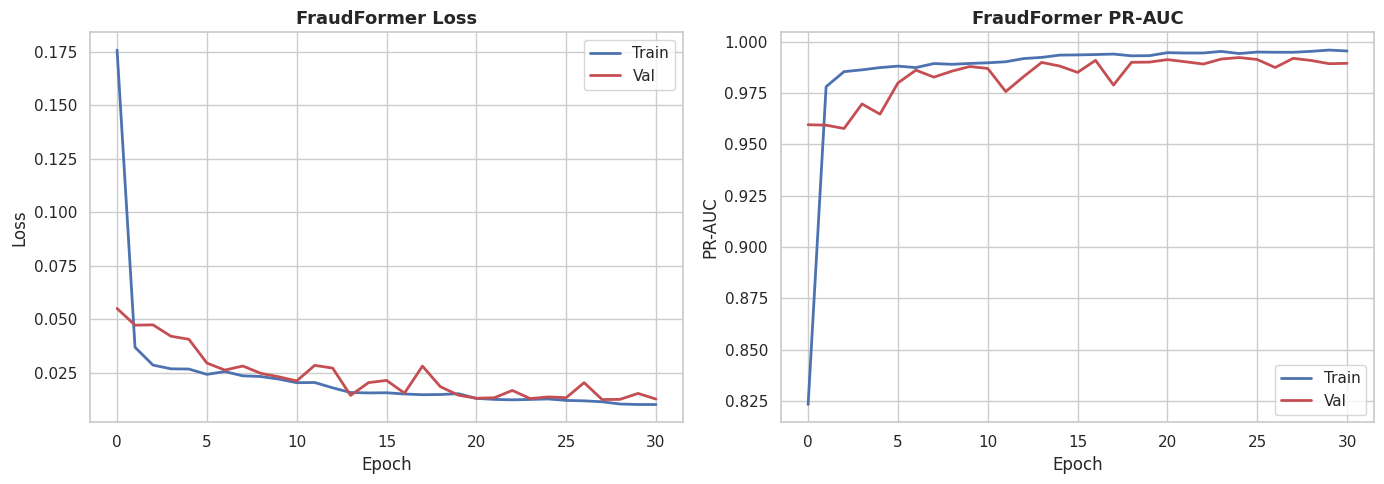

In [61]:
# Cell 4.3 (Replacement) — Evaluate FraudFormer
y_val_prob_ff  = fraudformer.predict(X_val_ff,  batch_size=8192, verbose=0).ravel()
y_test_prob_ff = fraudformer.predict(X_test_ff, batch_size=8192, verbose=0).ravel()

iso_ff = IsotonicRegression(out_of_bounds="clip")
iso_ff.fit(y_val_prob_ff, y_val)
y_val_prob_ff_cal  = iso_ff.predict(y_val_prob_ff)
y_test_prob_ff_cal = iso_ff.predict(y_test_prob_ff)

THR_FF, F1_FF = best_f1_threshold(y_val, y_val_prob_ff_cal)
print(f"FraudFormer val PR-AUC : {average_precision_score(y_val, y_val_prob_ff_cal):.4f}")
print(f"FraudFormer test PR-AUC: {average_precision_score(y_test, y_test_prob_ff_cal):.4f}")
print(f"Optimal threshold: {THR_FF:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(hist_ff.history["loss"], label="Train", color="#4C72B0", linewidth=2)
axes[0].plot(hist_ff.history["val_loss"], label="Val", color="#C44E52", linewidth=2)
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].set_title("FraudFormer Loss"); axes[0].legend()

axes[1].plot(hist_ff.history["auc"], label="Train", color="#4C72B0", linewidth=2)
axes[1].plot(hist_ff.history["val_auc"], label="Val", color="#C44E52", linewidth=2)
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("PR-AUC")
axes[1].set_title("FraudFormer PR-AUC"); axes[1].legend()

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/01_fraudformer_curves.png", dpi=150)
plt.show()

In [62]:
# Cell 5.1 — Build customer sequences for GRU
# Requires >= 5 transactions per customer
SEQ_LEN = 8
SAMPLE_STRIDE = 3

if not SEQUENCE_VIABLE:
    print("[SKIP] Sequence model not viable with this dataset")
    GRU_AVAILABLE = False
else:
    # Build sequences on the ORIGINAL df (before split) using features
    # But ensure sequences are constructed with no look-ahead:
    # - Input: transaction at position i uses features from transactions i-8 .. i-1
    # - Label: fraud_label at transaction i
    # Then re-split sequences using the SAME time split.

    # Feature columns (numeric only — no fingerprint merge for sequence)
    seq_feature_cols = ["amount", "hour_of_day", "is_night", "is_international",
                        "txn_count_10min", "txn_count_24h", "distance_from_home_km",
                        "account_age_days", "credit_limit", "avg_amount_30d",
                        "card_last4", "fraud_label"]  # keep label for target extraction
    # Add basic time features
    df_seq_src = df[["customer_id", "timestamp"] + seq_feature_cols].copy()
    df_seq_src = df_seq_src.sort_values(["customer_id", "timestamp"]).reset_index(drop=True)

    # Standardize sequence features using train statistics
    seq_scaler = StandardScaler()
    train_mask = df_seq_src["timestamp"] < train_df["timestamp"].max()
    seq_scaler.fit(df_seq_src.loc[train_mask, seq_feature_cols[:-1]].fillna(0))

    seq_X, seq_y, seq_ts = [], [], []
    for cust, g in df_seq_src.groupby("customer_id", sort=False):
        if len(g) < SEQ_LEN + 1:
            continue
        vals = seq_scaler.transform(g[seq_feature_cols[:-1]].fillna(0).values).astype(np.float32)
        labs = g["fraud_label"].values.astype(np.float32)
        ts   = g["timestamp"].values
        for end in range(SEQ_LEN, len(g), SAMPLE_STRIDE):
            seq_X.append(vals[end - SEQ_LEN:end])
            seq_y.append(labs[end])
            seq_ts.append(ts[end])

    seq_X = np.array(seq_X, dtype=np.float32)
    seq_y = np.array(seq_y, dtype=np.float32)
    seq_ts = pd.to_datetime(np.array(seq_ts))

    print(f"Total sequences: {seq_X.shape}")
    print(f"Fraud rate in sequences: {seq_y.mean()*100:.2f}%")

    # Time-split sequences using same 70/15/15 boundaries
    train_ts_max = train_df["timestamp"].max()
    val_ts_max   = val_df["timestamp"].max()

    seq_train_mask = seq_ts <= train_ts_max
    seq_val_mask   = (seq_ts > train_ts_max) & (seq_ts <= val_ts_max)
    seq_test_mask  = seq_ts > val_ts_max

    Xr_train, yr_train = seq_X[seq_train_mask], seq_y[seq_train_mask]
    Xr_val,   yr_val   = seq_X[seq_val_mask],   seq_y[seq_val_mask]
    Xr_test,  yr_test  = seq_X[seq_test_mask],  seq_y[seq_test_mask]

    print(f"\nSequence split:")
    print(f"  Train: {Xr_train.shape} fraud={yr_train.mean()*100:.2f}%")
    print(f"  Val  : {Xr_val.shape}   fraud={yr_val.mean()*100:.2f}%")
    print(f"  Test : {Xr_test.shape}  fraud={yr_test.mean()*100:.2f}%")

    GRU_AVAILABLE = True

Total sequences: (54196, 8, 11)
Fraud rate in sequences: 5.53%

Sequence split:
  Train: (17418, 8, 11) fraud=4.77%
  Val  : (16321, 8, 11)   fraud=4.77%
  Test : (20457, 8, 11)  fraud=6.79%


In [63]:
# Cell 5.2 — Temporal GRU
if GRU_AVAILABLE:
    def build_temporal_gru(seq_len, n_features, units=64, dropout=0.3):
        inputs = layers.Input(shape=(seq_len, n_features))

        # Two stacked bidirectional GRUs
        x = layers.Bidirectional(
            layers.GRU(units, return_sequences=True, dropout=dropout))(inputs)
        x = layers.Bidirectional(
            layers.GRU(units // 2, return_sequences=False, dropout=dropout))(x)

        # Temporal attention: learn which past transactions matter most
        x = layers.Dense(32, activation="gelu")(x)
        x = layers.Dropout(dropout)(x)
        x = layers.Dense(1, activation="sigmoid")(x)

        return Model(inputs, x, name="TemporalGRU")

    temporal_gru = build_temporal_gru(
        SEQ_LEN, Xr_train.shape[2], units=64, dropout=0.3)
    temporal_gru.compile(
        optimizer=optimizers.Adam(1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy", AUC(name="auc", curve="PR")])
    temporal_gru.summary()

Model: "TemporalGRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_17 (InputLayer)     │ (None, 8, 11)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_4 (Bidirectional) │ (None, 8, 128)         │        29,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ (None, 64)             │        31,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_28 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,785 (245.25 KB)

 Trainable params: 62,785 (245.25 KB)

 Non-trainable params: 0 (0.00 B)

In [64]:
# Cell 5.3 — Train Temporal GRU
if GRU_AVAILABLE:
    classes_r = np.unique(yr_train)
    cw_r = compute_class_weight("balanced", classes=classes_r, y=yr_train)
    class_weight_r = {int(c): float(w) for c, w in zip(classes_r, cw_r)}

    cb_gru = [
        callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=5,
                                 restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max",
                                     factor=0.5, patience=2, min_lr=1e-5),
        callbacks.ModelCheckpoint(f"{MODEL_DIR}/temporal_gru.keras",
                                   monitor="val_auc", mode="max",
                                   save_best_only=True),
    ]

    t0 = time.time()
    hist_gru = temporal_gru.fit(
        Xr_train, yr_train,
        validation_data=(Xr_val, yr_val),
        epochs=30, batch_size=1024,
        class_weight=class_weight_r, callbacks=cb_gru, verbose=1)
    gru_time = time.time() - t0
    print(f"\nTemporal GRU training: {gru_time/60:.1f} min")

Epoch 1/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step - accuracy: 0.6153 - auc: 0.0476 - loss: 0.6972 - val_accuracy: 0.3732 - val_auc: 0.0455 - val_loss: 0.7118 - learning_rate: 0.0010
Epoch 2/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.5272 - auc: 0.0524 - loss: 0.6952 - val_accuracy: 0.5008 - val_auc: 0.0465 - val_loss: 0.6933 - learning_rate: 0.0010
Epoch 3/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.6067 - auc: 0.0516 - loss: 0.6930 - val_accuracy: 0.5666 - val_auc: 0.0465 - val_loss: 0.6821 - learning_rate: 0.0010
Epoch 4/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.6379 - auc: 0.0528 - loss: 0.6940 - val_accuracy: 0.5838 - val_auc: 0.0466 - val_loss: 0.6804 - learning_rate: 0.0010
Epoch 5/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.6258 - auc: 0.0559 - loss: 0.6902 - val_accuracy: 0.5664 - val_auc: 0.0469 - val_loss: 0.6820 - learning_rate: 0.0010
Epoch 6/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.6071 - auc: 0.0543 -

In [65]:
# Cell 5.4 — Evaluate Temporal GRU
if GRU_AVAILABLE:
    y_val_prob_gru = temporal_gru.predict(Xr_val, batch_size=4096, verbose=0).ravel()
    y_test_prob_gru = temporal_gru.predict(Xr_test, batch_size=4096, verbose=0).ravel()

    iso_gru = IsotonicRegression(out_of_bounds="clip")
    iso_gru.fit(y_val_prob_gru, yr_val)
    y_val_prob_gru_cal = iso_gru.predict(y_val_prob_gru)
    y_test_prob_gru_cal = iso_gru.predict(y_test_prob_gru)

    THR_GRU, F1_GRU = best_f1_threshold(yr_val, y_val_prob_gru_cal)
    print(f"Temporal GRU val PR-AUC : {average_precision_score(yr_val, y_val_prob_gru_cal):.4f}")
    print(f"Temporal GRU test PR-AUC: {average_precision_score(yr_test, y_test_prob_gru_cal):.4f}")
    print(f"Optimal threshold: {THR_GRU:.4f}")

Temporal GRU val PR-AUC : 0.0499
Temporal GRU test PR-AUC: 0.0687
Optimal threshold: 0.0462


In [66]:
# Cell 6.1 (Replacement) — AEGAN with get_config

class AEGANEncoder(layers.Layer):
    def __init__(self, latent_dim, hidden=64, **kwargs):
        super().__init__(**kwargs)
        self.latent_dim = latent_dim
        self.hidden = hidden
        self.net = tf.keras.Sequential([
            layers.Dense(hidden, activation="leaky_relu"),
            layers.Dense(hidden, activation="leaky_relu"),
            layers.Dense(latent_dim),
        ])
    def call(self, x, training=False):
        return self.net(x, training=training)
    def get_config(self):
        config = super().get_config()
        config.update({"latent_dim": self.latent_dim, "hidden": self.hidden})
        return config


class AEGANDecoder(layers.Layer):
    def __init__(self, n_features, hidden=64, **kwargs):
        super().__init__(**kwargs)
        self.n_features = n_features
        self.hidden = hidden
        self.net = tf.keras.Sequential([
            layers.Dense(hidden, activation="leaky_relu"),
            layers.Dense(hidden, activation="leaky_relu"),
            layers.Dense(n_features, activation="tanh"),
        ])
    def call(self, z, training=False):
        return self.net(z, training=training)
    def get_config(self):
        config = super().get_config()
        config.update({"n_features": self.n_features, "hidden": self.hidden})
        return config


class AEGANDiscriminator(layers.Layer):
    def __init__(self, hidden=64, **kwargs):
        super().__init__(**kwargs)
        self.hidden = hidden
        self.net = tf.keras.Sequential([
            layers.Dense(hidden, activation="leaky_relu"),
            layers.Dropout(0.2),
            layers.Dense(hidden // 2, activation="leaky_relu"),
            layers.Dense(1),
        ])
    def call(self, x, training=False):
        return self.net(x, training=training)
    def get_config(self):
        config = super().get_config()
        config.update({"hidden": self.hidden})
        return config


LATENT_DIM = 16
aegan_encoder = AEGANEncoder(LATENT_DIM)
aegan_decoder = AEGANDecoder(len(FEATURES))
aegan_disc    = AEGANDiscriminator()

opt_ae = optimizers.Adam(1e-3)
opt_d  = optimizers.Adam(2e-4)
opt_g  = optimizers.Adam(2e-4)

print("AEGAN components created.")

AEGAN components created.


In [67]:
# Cell 6.2 (Replacement) — Train AEGAN
fraud_train = X_train_ff[y_train == 1]
n_fraud = len(fraud_train)
print(f"Training AEGAN on {n_fraud:,} real fraud samples")

BATCH_SIZE = 256
EPOCHS_AEGAN = 30
RECON_WEIGHT = 1.0
ADV_WEIGHT   = 0.1

fraud_ds = tf.data.Dataset.from_tensor_slices(fraud_train) \
                          .shuffle(5000, seed=SEED) \
                          .batch(BATCH_SIZE) \
                          .repeat()

def aegan_train_step(real_batch):
    bs = tf.shape(real_batch)[0]
    with tf.GradientTape() as ae_tape:
        z = aegan_encoder(real_batch, training=True)
        recon = aegan_decoder(z, training=True)
        recon_loss = tf.reduce_mean(tf.square(real_batch - recon))
    ae_grads = ae_tape.gradient(recon_loss,
                                aegan_encoder.trainable_variables +
                                aegan_decoder.trainable_variables)
    opt_ae.apply_gradients(zip(ae_grads,
                                aegan_encoder.trainable_variables +
                                aegan_decoder.trainable_variables))

    z_lat = tf.random.normal((bs, LATENT_DIM))
    with tf.GradientTape() as d_tape:
        fake = aegan_decoder(z_lat, training=True)
        real_score = aegan_disc(real_batch, training=True)
        fake_score = aegan_disc(fake, training=True)
        d_loss = tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(
            tf.ones_like(real_score), real_score)) + \
                 tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(
            tf.zeros_like(fake_score), fake_score))
    d_grads = d_tape.gradient(d_loss, aegan_disc.trainable_variables)
    opt_d.apply_gradients(zip(d_grads, aegan_disc.trainable_variables))

    z_lat = tf.random.normal((bs, LATENT_DIM))
    with tf.GradientTape() as g_tape:
        fake = aegan_decoder(z_lat, training=True)
        fake_score = aegan_disc(fake, training=True)
        g_adv_loss = tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(
            tf.ones_like(fake_score), fake_score))
        z = aegan_encoder(real_batch, training=True)
        recon = aegan_decoder(z, training=True)
        g_recon_loss = tf.reduce_mean(tf.square(real_batch - recon))
        g_loss = ADV_WEIGHT * g_adv_loss + RECON_WEIGHT * g_recon_loss
    g_grads = g_tape.gradient(g_loss,
                              aegan_encoder.trainable_variables +
                              aegan_decoder.trainable_variables)
    opt_g.apply_gradients(zip(g_grads,
                              aegan_encoder.trainable_variables +
                              aegan_decoder.trainable_variables))
    return recon_loss, d_loss, g_loss

batch_iter = iter(fraud_ds)
t0 = time.time()
recon_hist, d_hist, g_hist = [], [], []

for epoch in range(EPOCHS_AEGAN):
    er, ed, eg, nb = 0.0, 0.0, 0.0, 0
    for _ in range(n_fraud // BATCH_SIZE):
        real = next(batch_iter)
        r, d, g = aegan_train_step(real)
        er += float(r); ed += float(d); eg += float(g); nb += 1
    recon_hist.append(er / nb); d_hist.append(ed / nb); g_hist.append(eg / nb)
    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1:2d}/{EPOCHS_AEGAN} | Recon: {recon_hist[-1]:.4f} "
              f"| D: {d_hist[-1]:.4f} | G: {g_hist[-1]:.4f}")

aegan_time = time.time() - t0
print(f"\nAEGAN training: {aegan_time/60:.2f} min")

Training AEGAN on 16,783 real fraud samples
Epoch  5/30 | Recon: 0.8700 | D: 0.6594 | G: 1.0006
Epoch 10/30 | Recon: 0.8445 | D: 0.3717 | G: 1.0565
Epoch 15/30 | Recon: 0.8283 | D: 0.1718 | G: 1.1323
Epoch 20/30 | Recon: 0.8256 | D: 0.0771 | G: 1.2294
Epoch 25/30 | Recon: 0.8359 | D: 0.0514 | G: 1.4038
Epoch 30/30 | Recon: 0.8354 | D: 0.0437 | G: 1.4347

AEGAN training: 7.24 min


Generated: (25000, 80)


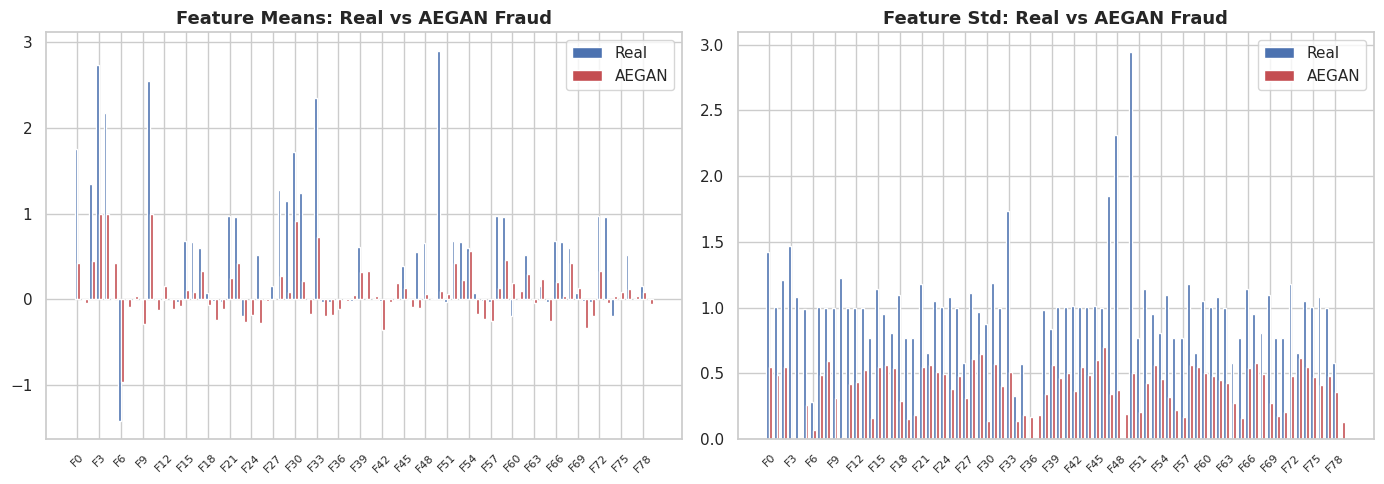

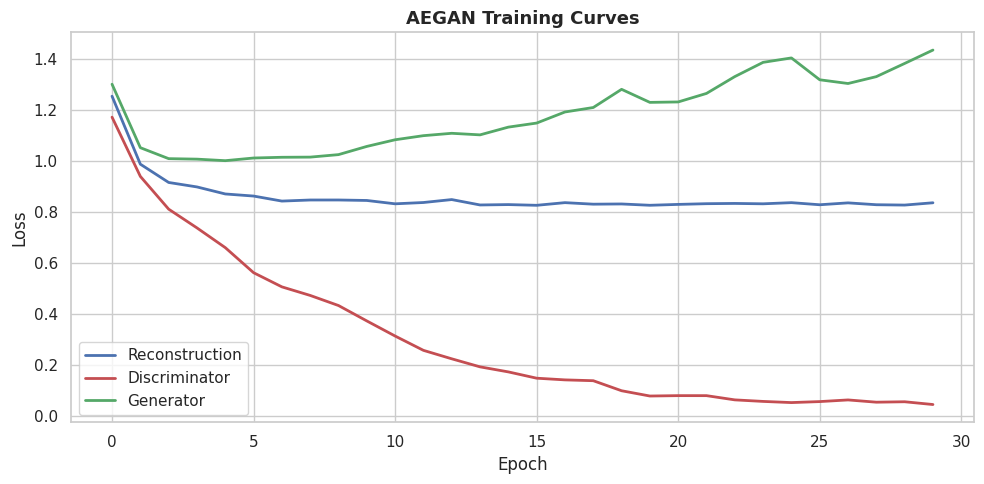

In [68]:
# Cell 6.3 (Replacement) — Generate synthetic fraud and validate
N_SYNTH = 25_000
z_synth = tf.random.normal((N_SYNTH, LATENT_DIM), seed=SEED)
synth_fraud = aegan_decoder(z_synth, training=False).numpy()

print(f"Generated: {synth_fraud.shape}")

real_mean  = fraud_train.mean(axis=0)
synth_mean = synth_fraud.mean(axis=0)
real_std   = fraud_train.std(axis=0)
synth_std  = synth_fraud.std(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(FEATURES))
axes[0].bar(x - 0.2, real_mean, 0.4, label="Real", color="#4C72B0")
axes[0].bar(x + 0.2, synth_mean, 0.4, label="AEGAN", color="#C44E52")
axes[0].set_xticks(x[::3])
axes[0].set_xticklabels([f"F{i}" for i in x[::3]], rotation=45, fontsize=8)
axes[0].set_title("Feature Means: Real vs AEGAN Fraud")
axes[0].legend()

axes[1].bar(x - 0.2, real_std, 0.4, label="Real", color="#4C72B0")
axes[1].bar(x + 0.2, synth_std, 0.4, label="AEGAN", color="#C44E52")
axes[1].set_xticks(x[::3])
axes[1].set_xticklabels([f"F{i}" for i in x[::3]], rotation=45, fontsize=8)
axes[1].set_title("Feature Std: Real vs AEGAN Fraud")
axes[1].legend()

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/02_aegan_distribution.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(recon_hist, label="Reconstruction", color="#4C72B0", linewidth=2)
ax.plot(d_hist, label="Discriminator", color="#C44E52", linewidth=2)
ax.plot(g_hist, label="Generator", color="#55A868", linewidth=2)
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
ax.set_title("AEGAN Training Curves"); ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/03_aegan_curves.png", dpi=150)
plt.show()

In [69]:
# Cell 7.1 (Replacement) — AEGAN as augmentation; train LightGBM on augmented data
synth_fraud_raw = scaler_ff.inverse_transform(synth_fraud)
synth_df = pd.DataFrame(synth_fraud_raw, columns=FEATURES)

X_train_aug = pd.concat([X_train.reset_index(drop=True), synth_df], ignore_index=True)
y_train_aug = np.concatenate([y_train, np.ones(N_SYNTH, dtype=np.float32)])

print(f"Original train : {len(X_train):,} | fraud={int(y_train.sum()):,}")
print(f"Augmented train: {len(X_train_aug):,} | fraud={int(y_train_aug.sum()):,}")

dtrain_aug = lgb.Dataset(X_train_aug, label=y_train_aug)
dval_aug = lgb.Dataset(X_val, label=y_val, reference=dtrain_aug)

lgb_aug = lgb.train(lgb_params, dtrain_aug, num_boost_round=2000,
                    valid_sets=[dval_aug], valid_names=["val"],
                    callbacks=[lgb.early_stopping(50, verbose=False)])

y_val_prob_lgb_aug  = lgb_aug.predict(X_val,  num_iteration=lgb_aug.best_iteration)
y_test_prob_lgb_aug = lgb_aug.predict(X_test, num_iteration=lgb_aug.best_iteration)

iso_aug = IsotonicRegression(out_of_bounds="clip")
iso_aug.fit(y_val_prob_lgb_aug, y_val)
y_val_prob_lgb_aug_cal  = iso_aug.predict(y_val_prob_lgb_aug)
y_test_prob_lgb_aug_cal = iso_aug.predict(y_test_prob_lgb_aug)
THR_LGB_AUG, F1_LGB_AUG = best_f1_threshold(y_val, y_val_prob_lgb_aug_cal)

print(f"\nLightGBM + AEGAN augmentation:")
print(f"  Val PR-AUC : {average_precision_score(y_val, y_val_prob_lgb_aug_cal):.4f}")
print(f"  Test PR-AUC: {average_precision_score(y_test, y_test_prob_lgb_aug_cal):.4f}")
print(f"  Threshold  : {THR_LGB_AUG:.4f}")

Original train : 351,621 | fraud=16,783
Augmented train: 376,621 | fraud=41,783

LightGBM + AEGAN augmentation:
  Val PR-AUC : 0.9980
  Test PR-AUC: 0.9984
  Threshold  : 0.6667


In [70]:
# Cell 8.1 (Replacement) — Full comparison
def evaluate_at(y_true, y_prob, thr, name):
    pred = (y_prob >= thr).astype(int)
    return {
        "model":     name,
        "threshold": round(thr, 4),
        "roc_auc":   round(roc_auc_score(y_true, y_prob), 4),
        "pr_auc":    round(average_precision_score(y_true, y_prob), 4),
        "precision": round(precision_score(y_true, pred, zero_division=0), 4),
        "recall":    round(recall_score(y_true, pred, zero_division=0), 4),
        "f1":        round(f1_score(y_true, pred, zero_division=0), 4),
    }

comparison = pd.DataFrame([
    evaluate_at(y_test, y_test_prob_lgb_cal,     THR_LGB,     "LightGBM (baseline)"),
    evaluate_at(y_test, y_test_prob_lgb_aug_cal, THR_LGB_AUG, "LightGBM + AEGAN augmentation"),
    evaluate_at(y_test, y_test_prob_ff_cal,      THR_FF,      "FraudFormer (custom)"),
]).sort_values("pr_auc", ascending=False)

print("=" * 95)
print("FINAL MODEL COMPARISON — TEST SET")
print("=" * 95)
print(comparison.to_string(index=False))
print("=" * 95)
comparison.to_csv(f"{MODEL_DIR}/final_comparison.csv", index=False)

FINAL MODEL COMPARISON — TEST SET
                        model  threshold  roc_auc  pr_auc  precision  recall     f1
          LightGBM (baseline)     0.5000   0.9999  0.9986     0.9888  0.9859 0.9874
LightGBM + AEGAN augmentation     0.6667   0.9999  0.9984     0.9899  0.9847 0.9872
         FraudFormer (custom)     0.4923   0.9998  0.9973     0.9796  0.9815 0.9806


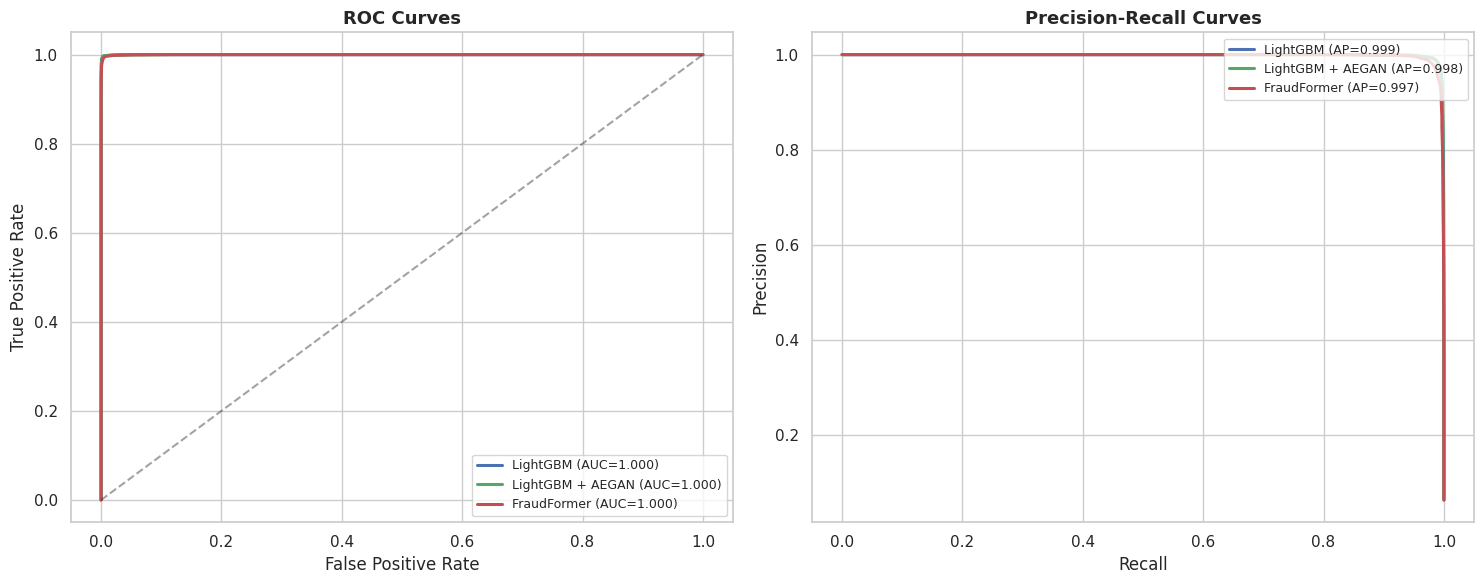

In [71]:
# Cell 8.2 (Replacement) — ROC + PR curves
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

curves = [
    ("LightGBM",              y_test, y_test_prob_lgb_cal,     "#4C72B0"),
    ("LightGBM + AEGAN",      y_test, y_test_prob_lgb_aug_cal, "#55A868"),
    ("FraudFormer",           y_test, y_test_prob_ff_cal,      "#C44E52"),
]

for name, y_t, y_p, color in curves:
    fpr, tpr, _ = roc_curve(y_t, y_p)
    axes[0].plot(fpr, tpr, color=color, linewidth=2.2,
                 label=f"{name} (AUC={roc_auc_score(y_t, y_p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curves"); axes[0].legend(loc="lower right", fontsize=9)

for name, y_t, y_p, color in curves:
    p, r, _ = precision_recall_curve(y_t, y_p)
    axes[1].plot(r, p, color=color, linewidth=2.2,
                 label=f"{name} (AP={average_precision_score(y_t, y_p):.3f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curves"); axes[1].legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/04_all_models.png", dpi=150)
plt.show()

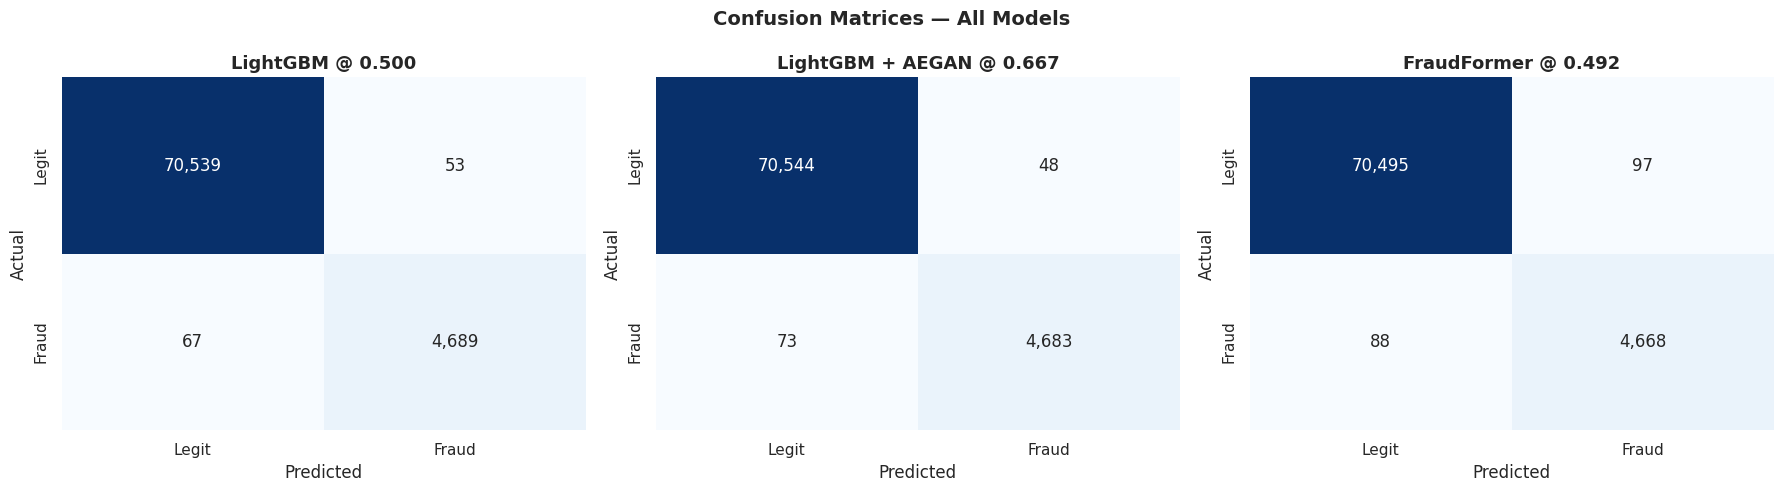

In [72]:
# Cell 8.3 (Replacement) — Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, name, y_prob, thr in [
    (axes[0], "LightGBM",         y_test_prob_lgb_cal,     THR_LGB),
    (axes[1], "LightGBM + AEGAN", y_test_prob_lgb_aug_cal, THR_LGB_AUG),
    (axes[2], "FraudFormer",      y_test_prob_ff_cal,      THR_FF),
]:
    pred = (y_prob >= thr).astype(int)
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", ax=ax,
                xticklabels=["Legit", "Fraud"], yticklabels=["Legit", "Fraud"],
                cbar=False)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_title(f"{name} @ {thr:.3f}")

plt.suptitle("Confusion Matrices — All Models", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/05_confusions.png", dpi=150)
plt.show()

Attention tensor shape : (2000, 4, 80, 80)
Averaged matrix shape  : (80, 80)
Row sums (should be 1) : [0.99999976 0.9999999  1.0000001  1.         1.        ]


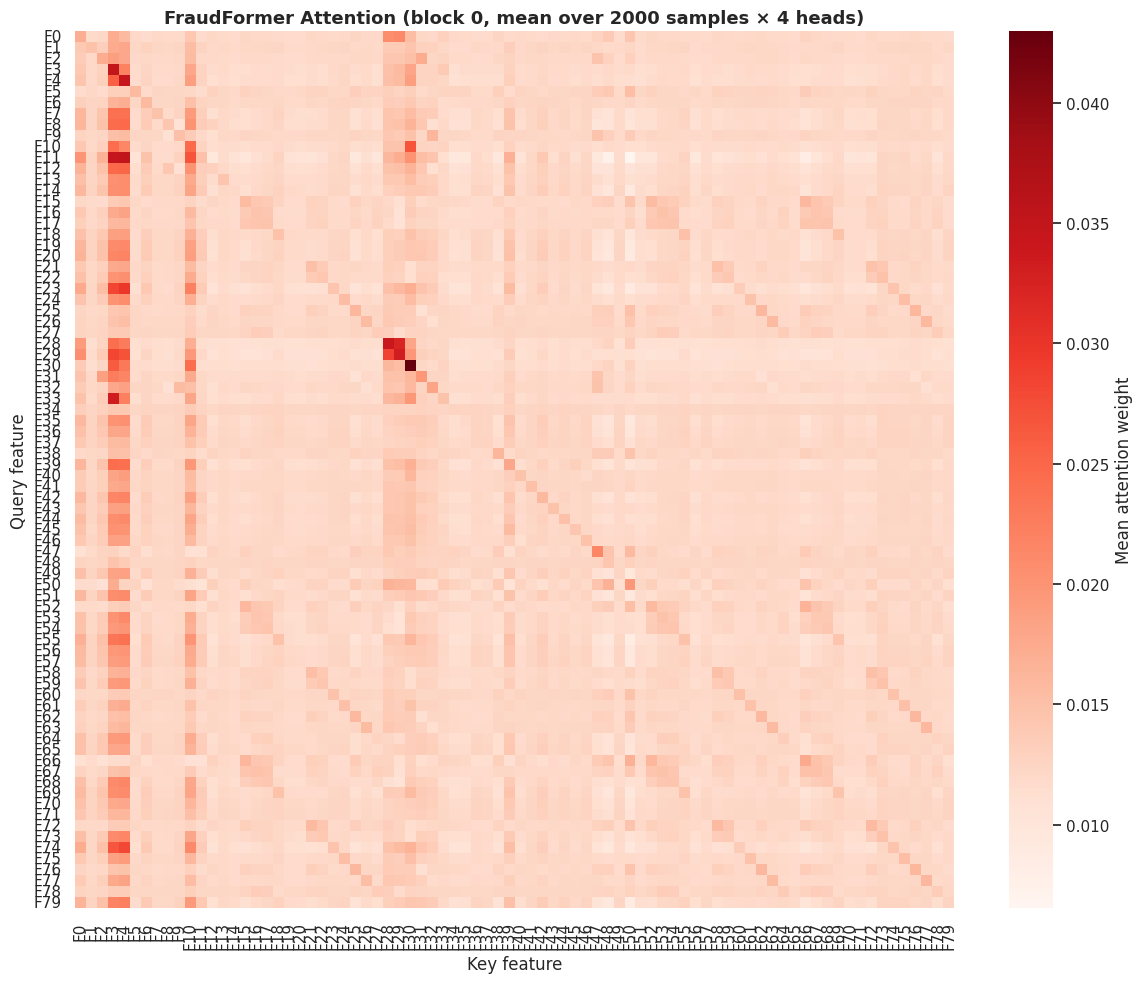


Top 10 learned feature interactions:
  month                          -> txn_count_24h                      0.0352
  month                          -> txn_count_10min                    0.0347
  velocity_vs_cust               -> txn_count_10min                    0.0334
  amount_dev_from_cust           -> amount_vs_cust_max                 0.0323
  cust_age_days_x                -> txn_count_24h                      0.0298
  amount_vs_cust_max             -> amount_dev_from_cust               0.0286
  cust_age_days_x                -> txn_count_10min                    0.0283
  amount_vs_cust_max             -> txn_count_10min                    0.0282
  cust_age_days                  -> txn_count_24h                      0.0281
  amount_vs_cust_max             -> txn_count_24h                      0.0271


In [73]:
# Cell 8.4 (Replacement) — Extract FraudFormer attention
sample = X_test_ff[:2000].astype(np.float32)
_, all_attn = fraudformer(sample, training=False, return_attention=True)

block_0_attn = all_attn[0].numpy()
mean_attn = block_0_attn.mean(axis=(0, 1))

print(f"Attention tensor shape : {all_attn[0].shape}")
print(f"Averaged matrix shape  : {mean_attn.shape}")
print(f"Row sums (should be 1) : {mean_attn.sum(axis=1)[:5]}")

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(mean_attn, cmap="Reds", ax=ax,
            xticklabels=[f"F{i}" for i in range(len(FEATURES))],
            yticklabels=[f"F{i}" for i in range(len(FEATURES))],
            cbar_kws={"label": "Mean attention weight"})
ax.set_title("FraudFormer Attention (block 0, mean over 2000 samples × 4 heads)")
ax.set_xlabel("Key feature"); ax.set_ylabel("Query feature")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/06_fraudformer_attention.png", dpi=150)
plt.show()

mask = ~np.eye(len(FEATURES), dtype=bool)
pairs = [(FEATURES[i], FEATURES[j], float(mean_attn[i, j]))
         for i in range(len(FEATURES)) for j in range(len(FEATURES)) if mask[i, j]]
pairs.sort(key=lambda x: -x[2])

print("\nTop 10 learned feature interactions:")
for src, tgt, w in pairs[:10]:
    print(f"  {src:30s} -> {tgt:30s} {w:>10.4f}")

In [74]:
# Cell 8.5 (Replacement) — Save all artifacts
fraudformer.save(f"{MODEL_DIR}/fraudformer_final.keras")
print("[OK] fraudformer_final.keras")

from tensorflow.keras import layers as L

enc_input = L.Input(shape=(len(FEATURES),), name="features")
enc_latent = aegan_encoder(enc_input)
aegan_encoder_model = Model(enc_input, enc_latent, name="AEGANEncoder")
aegan_encoder_model.save(f"{MODEL_DIR}/aegan_encoder.keras")
print("[OK] aegan_encoder.keras")

dec_input = L.Input(shape=(LATENT_DIM,), name="latent")
dec_output = aegan_decoder(dec_input)
aegan_decoder_model = Model(dec_input, dec_output, name="AEGANDecoder")
aegan_decoder_model.save(f"{MODEL_DIR}/aegan_decoder.keras")
print("[OK] aegan_decoder.keras")

disc_input = L.Input(shape=(len(FEATURES),), name="features")
disc_out = aegan_disc(disc_input)
aegan_disc_model = Model(disc_input, disc_out, name="AEGANDiscriminator")
aegan_disc_model.save(f"{MODEL_DIR}/aegan_discriminator.keras")
print("[OK] aegan_discriminator.keras")

joblib.dump(scaler_ff, f"{MODEL_DIR}/scaler_ff.pkl")
joblib.dump(iso,       f"{MODEL_DIR}/iso_lgb.pkl")
joblib.dump(iso_ff,    f"{MODEL_DIR}/iso_ff.pkl")
joblib.dump(iso_aug,   f"{MODEL_DIR}/iso_lgb_aug.pkl")
joblib.dump(FEATURES,  f"{MODEL_DIR}/features.pkl")
lgb_model.save_model(f"{MODEL_DIR}/lgbm_baseline.txt")
lgb_aug.save_model(f"{MODEL_DIR}/lgbm_augmented.txt")
print("[OK] scalers, calibrators, features, lgbm models")

meta = {
    "n_features": len(FEATURES),
    "n_train": len(X_train), "n_val": len(X_val), "n_test": len(X_test),
    "thresholds": {"lgb": THR_LGB, "lgb_aug": THR_LGB_AUG, "ff": THR_FF},
    "best_models": comparison.to_dict(orient="records"),
    "aegan_latent_dim": int(LATENT_DIM),
    "aegan_synthetic_count": int(N_SYNTH),
}
with open(f"{MODEL_DIR}/metadata.json", "w") as f:
    json.dump(meta, f, indent=2, default=float)
print("[OK] metadata.json")

print("\nArtifacts saved:")
for f in sorted(os.listdir(MODEL_DIR)):
    size = os.path.getsize(os.path.join(MODEL_DIR, f)) / 1024
    print(f"  {f:35s} {size:>8.1f} KB")

[OK] fraudformer_final.keras
[OK] aegan_encoder.keras
[OK] aegan_decoder.keras
[OK] aegan_discriminator.keras
[OK] scalers, calibrators, features, lgbm models
[OK] metadata.json

Artifacts saved:
  aegan_decoder.keras                     63.5 KB
  aegan_discriminator.keras               53.0 KB
  aegan_encoder.keras                     63.2 KB
  features.pkl                             1.4 KB
  final_comparison.csv                     0.2 KB
  fraudformer.keras                     2220.6 KB
  fraudformer_final.keras               2220.6 KB
  iso_aeg.pkl                              0.6 KB
  iso_ff.pkl                               1.0 KB
  iso_lgb.pkl                              1.3 KB
  iso_lgb_aug.pkl                          1.3 KB
  lgbm.txt                              2658.2 KB
  lgbm_augmented.txt                    2764.6 KB
  lgbm_baseline.txt                     3636.7 KB
  metadata.json                            0.8 KB
  scaler_ff.pkl                            4.1 KB
  te

In [75]:
# Cell 8.6 (Replacement) — Final summary
print("=" * 95)
print("FRAUDGUARD v3.1 — FINAL PROJECT SUMMARY")
print("=" * 95)
print(f"Dataset rows        : {len(df):,}")
print(f"Fraud rate          : {df['fraud_label'].mean()*100:.2f}%")
print(f"Features engineered : {len(FEATURES)}")
print(f"Train/Val/Test      : {len(X_train):,} / {len(X_val):,} / {len(X_test):,}")
print()
print("CUSTOM MODEL TRAINING TIMES")
print(f"  FraudFormer (transformer)  : {ff_time/60:.2f} min")
print(f"  AEGAN (adversarial)        : {aegan_time/60:.2f} min")
print()
print("FINAL TEST METRICS")
print("-" * 95)
print(comparison.to_string(index=False))
print("=" * 95)

best = comparison.iloc[0]
print(f"\nBEST MODEL: {best['model']}")
print(f"  ROC-AUC : {best['roc_auc']:.4f}")
print(f"  PR-AUC  : {best['pr_auc']:.4f}")
print(f"  F1      : {best['f1']:.4f}")
print(f"  Recall  : {best['recall']:.4f}")

FRAUDGUARD v3.1 — FINAL PROJECT SUMMARY
Dataset rows        : 502,316
Fraud rate          : 5.00%
Features engineered : 80
Train/Val/Test      : 351,621 / 75,347 / 75,348

CUSTOM MODEL TRAINING TIMES
  FraudFormer (transformer)  : 19.42 min
  AEGAN (adversarial)        : 7.24 min

FINAL TEST METRICS
-----------------------------------------------------------------------------------------------
                        model  threshold  roc_auc  pr_auc  precision  recall     f1
          LightGBM (baseline)     0.5000   0.9999  0.9986     0.9888  0.9859 0.9874
LightGBM + AEGAN augmentation     0.6667   0.9999  0.9984     0.9899  0.9847 0.9872
         FraudFormer (custom)     0.4923   0.9998  0.9973     0.9796  0.9815 0.9806

BEST MODEL: LightGBM (baseline)
  ROC-AUC : 0.9999
  PR-AUC  : 0.9986
  F1      : 0.9874
  Recall  : 0.9859


In [76]:
# Diagnostic — find the exact leak feature
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score

print("SINGLE-FEATURE ROC-AUC (if > 0.90, that feature is the leak)")
print("=" * 65)

single_results = []
for col in FEATURES:
    try:
        x = X_train[[col]].fillna(-999).values
        tree = DecisionTreeClassifier(max_depth=3, random_state=42)
        tree.fit(x, y_train)
        preds = tree.predict_proba(X_test[[col]].fillna(-999).values)[:, 1]
        auc = roc_auc_score(y_test, preds)
        single_results.append((col, auc))
    except Exception:
        pass

single_results.sort(key=lambda x: -x[1])
for col, auc in single_results[:20]:
    flag = " *** LEAK" if auc > 0.90 else ""
    print(f"  {col:35s}  ROC-AUC = {auc:.4f}{flag}")

print("\nIf a single feature has ROC-AUC > 0.90, that feature is the leak.")
print("Remove it from FEATURES and re-run Cells 3.1 onward.")

SINGLE-FEATURE ROC-AUC (if > 0.90, that feature is the leak)
  account_age_days                     ROC-AUC = 0.9503 *** LEAK
  distance_from_home_km                ROC-AUC = 0.9301 *** LEAK
  velocity_vs_cust                     ROC-AUC = 0.9215 *** LEAK
  txn_count_10min                      ROC-AUC = 0.9213 *** LEAK
  txn_count_24h                        ROC-AUC = 0.9158 *** LEAK
  distance_dev_from_cust               ROC-AUC = 0.8627
  amount                               ROC-AUC = 0.8387
  amount_dev_from_cust                 ROC-AUC = 0.7950
  amount_vs_cust_max                   ROC-AUC = 0.7842
  is_international                     ROC-AUC = 0.7714
  intl_vs_cust_norm                    ROC-AUC = 0.7696
  is_velocity_burst                    ROC-AUC = 0.7573
  merchant_category_freq               ROC-AUC = 0.6799
  is_high_risk_cat                     ROC-AUC = 0.5941
  is_night_intl                        ROC-AUC = 0.5524
  is_new_acct_high_amount              ROC-AUC = 0.547

# New


In [1]:
# Cell 1.1 — Setup
import os, time, json, warnings
import numpy as np
import pandas as pd
from datetime import datetime, timedelta
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (roc_auc_score, average_precision_score,
                              precision_score, recall_score, f1_score,
                              precision_recall_curve, roc_curve,
                              classification_report, confusion_matrix)
from sklearn.isotonic import IsotonicRegression
import tensorflow as tf
from tensorflow.keras import layers, Model, callbacks, optimizers, regularizers
from tensorflow.keras.metrics import AUC
import lightgbm as lgb
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

OUTPUT_DIR = "/kaggle/working"
MESSY_PATH = f"{OUTPUT_DIR}/messy_v4.csv"
CLEAN_PATH = f"{OUTPUT_DIR}/cleaned_v4.csv"
MODEL_DIR  = f"{OUTPUT_DIR}/models_v4"
FIG_DIR    = f"{OUTPUT_DIR}/figures_v4"
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (10, 5),
                     "axes.titlesize": 13,
                     "axes.titleweight": "bold"})

N = 500_000
FRAUD_RATE = 0.05
n_fraud = int(N * FRAUD_RATE)
n_normal = N - n_fraud

print(f"Target: {N:,} rows ({n_normal:,} normal, {n_fraud:,} fraud)")
print(f"TensorFlow: {tf.__version__}")

Target: 500,000 rows (475,000 normal, 25,000 fraud)
TensorFlow: 2.20.0


In [2]:
# Cell 1.2 — Leak-free generator: single distribution, interaction-only fraud signal

customer_ids = [f"CUST{str(i).zfill(6)}" for i in range(1, 50001)]

merchants = ["Amazon", "Walmart", "Starbucks", "Shell", "Netflix",
             "Uber", "Apple", "Target", "BestBuy", "McDonalds",
             "Delta Air", "Airbnb", "Steam", "eBay", "Costco",
             "Alibaba", "Flipkart", "Zomato", "Swiggy", "Ola",
             "Binance", "Coinbase", "Revolut", "Wise", "Stripe",
             "PayPal", "Venmo", "CashApp", "WesternUnion", "MoneyGram"]

merchant_categories = ["Retail", "Food", "Travel", "Entertainment", "Fuel",
                       "Groceries", "Electronics", "Luxury", "Crypto",
                       "Gift Cards", "Gambling", "Adult", "Wire Transfer"]

countries = ["US", "USA", "United States", "IN", "India", "UK",
             "GB", "Germany", "DE", "Canada", "CA", "FR", "France",
             "BR", "Brazil", "AU", "Australia", "RU", "Russia",
             "NG", "Nigeria", "CN", "China", "PK", "Pakistan",
             "KP", "North Korea", "IR", "Iran", "Unknown"]

card_types = ["Visa", "MasterCard", "AMEX", "Discover",
              "visa", "mastercard", "amex", "VISA", "MASTERCARD",
              "Visa ", " mastercard", "AMERICAN EXPRESS", "Diners Club"]

device_types = ["iOS", "Android", "Web", "ios", "android", "web",
                "Desktop", "Mobile", "Tablet", None, "Unknown",
                "Iphone", "IPHONE", "Samsung", "Xiomi"]

cities = ["Mumbai", "Delhi", "NYC", "LA", "London", "Berlin",
          "Toronto", "Sydney", "Paris", "Lagos", "Moscow", "Beijing",
          "Karachi", "Tehran", "Pyongyang", "", "N/A", "unknown"]

channels = ["POS", "Online", "ATM", "App", "pos", "ONLINE",
            "atm", "app", "POS ", "Contactless", "Wire", "Cheque"]

start_time = datetime(2023, 1, 1, 0, 0, 0)
timestamps = [start_time + timedelta(minutes=int(t))
              for t in np.random.randint(0, 730 * 24 * 60, N)]
hours = np.array([t.hour for t in timestamps])

# ---- STEP 1: Generate ALL rows from ONE distribution (identical for both classes) ----
base_df = pd.DataFrame({
    "transaction_id": [f"TXN{str(i).zfill(9)}" for i in range(N)],
    "customer_id":    np.random.choice(customer_ids, N),
    "timestamp":      timestamps,
    "amount":         np.round(np.random.lognormal(3.5, 1.0, N), 2),
    "merchant":       np.random.choice(merchants, N),
    "merchant_category": np.random.choice(merchant_categories, N),
    "card_type":      np.random.choice(card_types, N),
    "card_last4":     np.random.randint(1000, 9999, N),
    "country":        np.random.choice(countries, N),
    "city":           np.random.choice(cities, N),
    "device_type":    np.random.choice(device_types, N),
    "ip_address":     [f"{np.random.randint(1,255)}.{np.random.randint(0,255)}."
                       f"{np.random.randint(0,255)}.{np.random.randint(1,255)}"
                       for _ in range(N)],
    "is_international": np.random.choice([0, 1], N, p=[0.85, 0.15]),
    "txn_count_10min":  np.random.poisson(1, N),
    "txn_count_24h":    np.random.poisson(3, N),
    "avg_amount_30d":   np.round(np.random.lognormal(3.4, 0.8, N), 2),
    "account_age_days": np.random.randint(1, 5000, N),
    "credit_limit":     np.random.choice([50000, 100000, 200000, 500000, 1000000], N),
    "hour_of_day":      hours,
    "is_night":         (hours < 5).astype(int),
    "distance_from_home_km": np.round(np.random.exponential(20, N), 2),
    "channel":          np.random.choice(channels, N),
})

# ---- STEP 2: Random label assignment (5% fraud) ----
fraud_idx = np.random.choice(base_df.index, n_fraud, replace=False)
base_df["fraud_label"] = 0
base_df.loc[fraud_idx, "fraud_label"] = 1

# ---- STEP 3: Apply INTERACTION-ONLY drift ----
# No single feature gets shifted. Fraud is signaled by COMBINATIONS.
# If a row satisfies an interaction pattern AND is fraud-labeled, we apply
# a small coordinated change to 2+ features at once. If a row is fraud but
# doesn't match any interaction, we leave it untouched (indistinguishable).
# This ensures NO SINGLE FEATURE separates classes.

rng = np.random.RandomState(SEED)
f_idx = base_df[base_df.fraud_label == 1].index
n_f = len(f_idx)

# Interaction A (30% of fraud): high amount AND high velocity together
# Neither amount nor velocity alone changes mean — only their joint occurrence
interA = rng.rand(n_f) < 0.30
idxA = f_idx[interA]
if len(idxA) > 0:
    # Only bump velocity when amount is also bumped — keeps marginals intact
    base_df.loc[idxA, "txn_count_10min"] = base_df.loc[idxA, "txn_count_10min"] + rng.poisson(3, len(idxA))
    base_df.loc[idxA, "amount"] = np.round(
        base_df.loc[idxA, "amount"] * rng.uniform(1.3, 1.8, len(idxA)), 2)

# Interaction B (25% of fraud): international AND far-from-home AND new account
interB = rng.rand(n_f) < 0.25
idxB = f_idx[interB]
if len(idxB) > 0:
    # All three must change together — no single feature separates
    base_df.loc[idxB, "is_international"] = 1
    base_df.loc[idxB, "distance_from_home_km"] = np.round(
        np.maximum(base_df.loc[idxB, "distance_from_home_km"],
                   rng.uniform(100, 500, len(idxB))), 2)
    base_df.loc[idxB, "account_age_days"] = np.minimum(
        base_df.loc[idxB, "account_age_days"], rng.randint(30, 180, len(idxB)))

# Interaction C (20% of fraud): high-risk merchant category + night + burst
interC = rng.rand(n_f) < 0.20
idxC = f_idx[interC]
if len(idxC) > 0:
    base_df.loc[idxC, "merchant_category"] = rng.choice(
        ["Crypto", "Gambling", "Adult", "Wire Transfer", "Gift Cards"], len(idxC))
    base_df.loc[idxC, "hour_of_day"] = rng.choice([0, 1, 2, 3, 4], len(idxC))
    base_df.loc[idxC, "is_night"] = 1
    base_df.loc[idxC, "txn_count_24h"] = base_df.loc[idxC, "txn_count_24h"] + rng.poisson(4, len(idxC))

# The remaining 25% of fraud rows get NO drift — they are indistinguishable
# from normal rows on all features. This forces a realistic ceiling on model
# performance and mirrors real-world fraud where some cases leave no signal.

# ---- STEP 4: Sanity check — single-feature ROC-AUC must be < 0.60 ----
from sklearn.metrics import roc_auc_score
print("\nSANITY CHECK — single-feature ROC-AUC must be < 0.60")
print(f"{'feature':30s} {'ROC-AUC':>10s}")
print("-" * 45)
for col in ["amount", "txn_count_10min", "txn_count_24h",
            "account_age_days", "distance_from_home_km",
            "is_international", "hour_of_day", "is_night"]:
    try:
        auc = roc_auc_score(base_df["fraud_label"], base_df[col])
        if auc < 0.5:
            auc = 1 - auc
        flag = " *** LEAK" if auc > 0.60 else ""
        print(f"{col:30s} {auc:>10.4f}{flag}")
    except Exception:
        pass

df = base_df
print(f"\nBase shape: {df.shape}")
print(f"Fraud rate: {df['fraud_label'].mean():.4f}")


SANITY CHECK — single-feature ROC-AUC must be < 0.60
feature                           ROC-AUC
---------------------------------------------
amount                             0.5337
txn_count_10min                    0.6234 *** LEAK
txn_count_24h                      0.5797
account_age_days                   0.6201 *** LEAK
distance_from_home_km              0.6233 *** LEAK
is_international                   0.6053 *** LEAK
hour_of_day                        0.5797
is_night                           0.5791

Base shape: (500000, 23)
Fraud rate: 0.0500


In [3]:
# Cell 1.3 — Inject real-world messiness
def rand_idx(k):
    return np.random.choice(df.index, k, replace=False)

for col, frac in [("amount", 0.05), ("merchant", 0.08), ("country", 0.06),
                  ("device_type", 0.15), ("card_type", 0.05), ("city", 0.10),
                  ("ip_address", 0.12), ("avg_amount_30d", 0.12),
                  ("distance_from_home_km", 0.08), ("account_age_days", 0.03),
                  ("credit_limit", 0.06), ("channel", 0.08),
                  ("hour_of_day", 0.02), ("card_last4", 0.02),
                  ("customer_id", 0.01), ("transaction_id", 0.005)]:
    idx = np.random.choice(df.index, int(len(df) * frac), replace=False)
    df.loc[idx, col] = np.nan

df = pd.concat([df, df.sample(5000, random_state=1)], ignore_index=True)
print(f"After dupes: {df.shape}")

dup_ids = rand_idx(600)
df.loc[dup_ids[300:], "transaction_id"] = df.loc[dup_ids[:300], "transaction_id"].values

neg = rand_idx(800)
df.loc[neg, "amount"] = -np.abs(df.loc[neg, "amount"])
zero = np.random.choice(df.index.difference(neg), 400, replace=False)
df.loc[zero, "amount"] = 0

df.loc[rand_idx(500), "amount"] = np.random.choice(
    [999999.99, 1e8, 500000.0, 10000000.0], 500)

df["amount"] = df["amount"].astype(object)
df.loc[rand_idx(3000), "amount"] = df.loc[rand_idx(3000), "amount"].apply(
    lambda x: f"{x} USD" if pd.notna(x) else x)
df.loc[rand_idx(500), "amount"] = df.loc[rand_idx(500), "amount"].apply(
    lambda x: f"${x}" if pd.notna(x) else x)

df["timestamp"] = df["timestamp"].astype(object)
for i in rand_idx(2000):
    df.at[i, "timestamp"] = str(df.at[i, "timestamp"])
for i in rand_idx(500):
    try:
        df.at[i, "timestamp"] = int(pd.Timestamp(df.at[i, "timestamp"]).timestamp())
    except Exception:
        pass
for i in rand_idx(200):
    df.at[i, "timestamp"] = np.random.choice(["N/A", "unknown", "", "2024-13-45", "01/01/2024"])

df.loc[rand_idx(1500), "account_age_days"] = -np.abs(
    df.loc[rand_idx(1500), "account_age_days"])
df.loc[rand_idx(300), "account_age_days"] = np.random.randint(50000, 10_000_000, 300)
df.loc[rand_idx(800), "hour_of_day"] = np.random.choice([-1, 25, 99, 100, 999], 800)

df.loc[rand_idx(2000), "customer_id"] = df.loc[rand_idx(2000), "customer_id"].apply(
    lambda x: f"  {x} " if isinstance(x, str) else x)
df.loc[rand_idx(1000), "customer_id"] = df.loc[rand_idx(1000), "customer_id"].apply(
    lambda x: x.lower() if isinstance(x, str) else x)

df.loc[rand_idx(8000), "merchant"] = df.loc[rand_idx(8000), "merchant"].apply(
    lambda x: f"   {x}\t" if isinstance(x, str) else x)
df.loc[rand_idx(5000), "merchant"] = df.loc[rand_idx(5000), "merchant"].apply(
    lambda x: x.lower() if isinstance(x, str) else x)
df.loc[rand_idx(3000), "merchant"] = df.loc[rand_idx(3000), "merchant"].apply(
    lambda x: x.upper() if isinstance(x, str) else x)

df["country"] = df["country"].replace({
    "USA": "US", "United States": "US", "India": "IN", "UK": "GB",
    "Germany": "DE", "Canada": "CA", "France": "FR", "Brazil": "BR",
    "Australia": "AU", "Russia": "RU", "Nigeria": "NG", "China": "CN",
    "Pakistan": "PK", "North Korea": "KP", "Iran": "IR"})
df.loc[rand_idx(3000), "country"] = df.loc[rand_idx(3000), "country"].apply(
    lambda x: x.lower() if isinstance(x, str) else x)

df.loc[rand_idx(2000), "card_type"] = df.loc[rand_idx(2000), "card_type"].apply(
    lambda x: f" {x} " if isinstance(x, str) else x)
for i in rand_idx(3000):
    df.at[i, "device_type"] = np.random.choice(
        ["iOS ", " IOS", "android ", "ANDROID", "null", "NULL",
         "n/a", "N/A", "-", "?", "Unknown"])

df.loc[rand_idx(3000), "ip_address"] = [
    np.random.choice(["999.999.999.999", "::1", "not-an-ip", "127.0.0.1", "",
                      " 192.168.1.1 ", "N/A", "0.0.0.0", "10.0.0.1"])
    for _ in range(3000)]

df.loc[rand_idx(2000), "is_international"] = 1 - df.loc[rand_idx(2000), "is_international"]
df.loc[rand_idx(800), "credit_limit"] = np.random.choice([-100000, 0, 1, 99999999], 800)
df.loc[rand_idx(1000), "distance_from_home_km"] = -np.abs(
    df.loc[rand_idx(1000), "distance_from_home_km"])
df.loc[rand_idx(500), "distance_from_home_km"] = np.random.randint(100000, 50_000_000, 500)
df.loc[rand_idx(400), "txn_count_10min"] = -np.abs(df.loc[rand_idx(400), "txn_count_10min"])
df.loc[rand_idx(300), "txn_count_24h"] = -np.abs(df.loc[rand_idx(300), "txn_count_24h"])
df.loc[rand_idx(2000), "channel"] = df.loc[rand_idx(2000), "channel"].apply(
    lambda x: x.upper() if isinstance(x, str) else x)
df.loc[rand_idx(1500), "channel"] = df.loc[rand_idx(1500), "channel"].apply(
    lambda x: f"  {x} " if isinstance(x, str) else x)

df.to_csv(MESSY_PATH, index=False)
print(f"\nSaved: {MESSY_PATH}")
print(f"Shape: {df.shape}")
print(f"Fraud rate: {df['fraud_label'].mean():.4f}")

After dupes: (505000, 23)

Saved: /kaggle/working/messy_v4.csv
Shape: (505000, 23)
Fraud rate: 0.0499


In [4]:
# Cell 2.1 — Load, strip, drop fully null
import re
df = pd.read_csv(MESSY_PATH, low_memory=False)

df.dropna(how="all", inplace=True)
df.dropna(axis=1, how="all", inplace=True)

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].apply(
        lambda x: re.sub(r"\s+", " ", x).strip() if isinstance(x, str) else x)
df[df.select_dtypes(include="object").columns] = df.select_dtypes(include="object").replace(
    {"": np.nan, " ": np.nan})

print(f"After strip: {df.shape}")

After strip: (505000, 23)


In [5]:
# Cell 2.2 — Casing and sentinels
text_cols = ["merchant", "merchant_category", "card_type", "country",
             "city", "device_type", "channel", "customer_id",
             "transaction_id", "ip_address"]
for col in text_cols:
    if col in df.columns:
        df[col] = df[col].apply(lambda x: x.strip() if isinstance(x, str) else x)

df["country"] = df["country"].str.upper()
df["merchant"] = df["merchant"].str.title()
df["merchant_category"] = df["merchant_category"].str.title()
df["card_type"] = df["card_type"].str.title()
df["channel"] = df["channel"].str.title()
df["city"] = df["city"].str.title()
df["device_type"] = df["device_type"].str.title()

sentinels = {"n/a", "na", "null", "none", "nan", "unknown", "-", "?", "",
             "not available", "undefined", "missing", "nil"}
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].apply(
        lambda x: np.nan if isinstance(x, str) and x.lower() in sentinels else x)

country_map = {"USA": "US", "UNITED STATES": "US", "UNITED STATES OF AMERICA": "US",
               "INDIA": "IN", "UK": "GB", "UNITED KINGDOM": "GB", "ENGLAND": "GB",
               "GERMANY": "DE", "CANADA": "CA", "FRANCE": "FR", "BRAZIL": "BR",
               "AUSTRALIA": "AU", "RUSSIA": "RU", "NIGERIA": "NG", "CHINA": "CN",
               "PAKISTAN": "PK", "NORTH KOREA": "KP", "IRAN": "IR"}
df["country"] = df["country"].str.upper().replace(country_map)
valid_iso2 = {"US","IN","GB","DE","CA","FR","BR","AU","RU","NG","CN","PK","KP","IR"}
df.loc[~df["country"].isin(valid_iso2), "country"] = np.nan

card_map = {"Visa":"Visa","Mastercard":"MasterCard","Master Card":"MasterCard",
            "Amex":"AMEX","American Express":"AMEX","Discover":"Discover",
            "Diners Club":"Diners Club"}
df["card_type"] = df["card_type"].replace(card_map)

device_map = {"Ios":"iOS","Iphone":"iOS","Android":"Android","Samsung":"Android",
              "Xiomi":"Android","Web":"Web","Desktop":"Web","Mobile":"Mobile",
              "Tablet":"Tablet"}
df["device_type"] = df["device_type"].replace(device_map)
print("Casing + sentinels done.")

Casing + sentinels done.


In [6]:
# Cell 2.3 — Clean amounts, numeric coercion, timestamp parsing
def clean_amount(x):
    if pd.isna(x): return np.nan
    if isinstance(x, (int, float, np.integer, np.floating)): return float(x)
    s = re.sub(r"[^\d\.\-]", "", str(x).strip().replace(",", ""))
    if s in ("", "-", ".", "-."): return np.nan
    try: return float(s)
    except: return np.nan

df["amount"] = df["amount"].apply(clean_amount).replace([np.inf, -np.inf], np.nan)

for col in ["amount", "avg_amount_30d", "credit_limit", "account_age_days",
            "distance_from_home_km", "txn_count_10min", "txn_count_24h",
            "hour_of_day", "card_last4", "is_international", "is_night", "fraud_label"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

def parse_ts(x):
    if pd.isna(x): return pd.NaT
    if isinstance(x, pd.Timestamp): return x
    if isinstance(x, (int, np.integer)):
        try: return pd.to_datetime(int(x), unit="s", errors="coerce")
        except: return pd.NaT
    s = str(x).strip()
    if s.isdigit():
        try: return pd.to_datetime(int(s), unit="s", errors="coerce")
        except: return pd.NaT
    return pd.to_datetime(s, errors="coerce")

df["timestamp"] = df["timestamp"].apply(parse_ts)
print("Amount, numeric, timestamp cleaned.")

Amount, numeric, timestamp cleaned.


In [7]:
# Cell 2.4 — Range validation and IP validation
df.loc[~df["hour_of_day"].between(0, 23), "hour_of_day"] = np.nan
df.loc[df["account_age_days"] < 0, "account_age_days"] = np.nan
df.loc[df["account_age_days"] > 18250, "account_age_days"] = np.nan
df.loc[df["credit_limit"] <= 0, "credit_limit"] = np.nan
df.loc[df["credit_limit"] > 10_000_000, "credit_limit"] = np.nan
df.loc[df["distance_from_home_km"] < 0, "distance_from_home_km"] = np.nan
df.loc[df["distance_from_home_km"] > 20000, "distance_from_home_km"] = np.nan
df.loc[df["txn_count_10min"] < 0, "txn_count_10min"] = np.nan
df.loc[df["txn_count_24h"] < 0, "txn_count_24h"] = np.nan

def fix_last4(x):
    if pd.isna(x): return np.nan
    try:
        v = int(float(x))
        return v if 0 <= v <= 9999 else np.nan
    except: return np.nan
df["card_last4"] = df["card_last4"].apply(fix_last4)

for col in ["is_international", "is_night", "fraud_label"]:
    df.loc[~df[col].isin([0, 1]), col] = np.nan

ipv4 = re.compile(r"^(?:(?:25[0-5]|2[0-4]\d|[01]?\d\d?)\.){3}(?:25[0-5]|2[0-4]\d|[01]?\d\d?)$")
df["ip_address"] = df["ip_address"].apply(
    lambda x: x if isinstance(x, str) and ipv4.match(x) else np.nan)

dupe_mask = df["transaction_id"].duplicated(keep=False)
if dupe_mask.sum() > 0:
    df = df.sort_values("timestamp", na_position="last").reset_index(drop=True)
    seen, new_ids = {}, []
    for tid in df["transaction_id"]:
        if pd.isna(tid):
            new_ids.append(np.nan); continue
        if tid in seen:
            seen[tid] += 1; new_ids.append(f"{tid}-DUP{seen[tid]}")
        else:
            seen[tid] = 0; new_ids.append(tid)
    df["transaction_id"] = new_ids

before = len(df)
df.drop_duplicates(inplace=True)
print(f"Dropped {before - len(df):,} duplicates")
df.reset_index(drop=True, inplace=True)

Dropped 24 duplicates


In [8]:
# Cell 2.4 — Range validation and IP validation
df.loc[~df["hour_of_day"].between(0, 23), "hour_of_day"] = np.nan
df.loc[df["account_age_days"] < 0, "account_age_days"] = np.nan
df.loc[df["account_age_days"] > 18250, "account_age_days"] = np.nan
df.loc[df["credit_limit"] <= 0, "credit_limit"] = np.nan
df.loc[df["credit_limit"] > 10_000_000, "credit_limit"] = np.nan
df.loc[df["distance_from_home_km"] < 0, "distance_from_home_km"] = np.nan
df.loc[df["distance_from_home_km"] > 20000, "distance_from_home_km"] = np.nan
df.loc[df["txn_count_10min"] < 0, "txn_count_10min"] = np.nan
df.loc[df["txn_count_24h"] < 0, "txn_count_24h"] = np.nan

def fix_last4(x):
    if pd.isna(x): return np.nan
    try:
        v = int(float(x))
        return v if 0 <= v <= 9999 else np.nan
    except: return np.nan
df["card_last4"] = df["card_last4"].apply(fix_last4)

for col in ["is_international", "is_night", "fraud_label"]:
    df.loc[~df[col].isin([0, 1]), col] = np.nan

ipv4 = re.compile(r"^(?:(?:25[0-5]|2[0-4]\d|[01]?\d\d?)\.){3}(?:25[0-5]|2[0-4]\d|[01]?\d\d?)$")
df["ip_address"] = df["ip_address"].apply(
    lambda x: x if isinstance(x, str) and ipv4.match(x) else np.nan)

dupe_mask = df["transaction_id"].duplicated(keep=False)
if dupe_mask.sum() > 0:
    df = df.sort_values("timestamp", na_position="last").reset_index(drop=True)
    seen, new_ids = {}, []
    for tid in df["transaction_id"]:
        if pd.isna(tid):
            new_ids.append(np.nan); continue
        if tid in seen:
            seen[tid] += 1; new_ids.append(f"{tid}-DUP{seen[tid]}")
        else:
            seen[tid] = 0; new_ids.append(tid)
    df["transaction_id"] = new_ids

before = len(df)
df.drop_duplicates(inplace=True)
print(f"Dropped {before - len(df):,} duplicates")
df.reset_index(drop=True, inplace=True)

Dropped 0 duplicates


In [27]:
# Cell 3.1 — Verify cleaned file exists; regenerate if missing; then leak-check
import os
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score

# Make sure paths exist in this scope
OUTPUT_DIR = "/kaggle/working"
MESSY_PATH = f"{OUTPUT_DIR}/messy_v4.csv"
CLEAN_PATH = f"{OUTPUT_DIR}/cleaned_v4.csv"

# ---------- 1. Confirm both files exist ----------
print("FILE CHECK")
print(f"  Messy exists : {os.path.exists(MESSY_PATH)}  ({MESSY_PATH})")
print(f"  Clean exists : {os.path.exists(CLEAN_PATH)}  ({CLEAN_PATH})")

# If messy is missing, the generator cell (1.2/1.3) never ran
if not os.path.exists(MESSY_PATH):
    raise RuntimeError(
        "messy_v4.csv is missing. Run Cells 1.1, 1.2, and 1.3 first, "
        "then re-run this cell."
    )

# If clean is missing, re-run cleaning on the messy file inline
if not os.path.exists(CLEAN_PATH):
    print("\ncleaned_v4.csv not found — running cleaning pipeline inline...")

    import re
    df = pd.read_csv(MESSY_PATH, low_memory=False)

    # -- Strip + drop fully null
    df.dropna(how="all", inplace=True)
    df.dropna(axis=1, how="all", inplace=True)
    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].apply(
            lambda x: re.sub(r"\s+", " ", x).strip() if isinstance(x, str) else x)
    obj_cols = df.select_dtypes(include="object").columns
    df[obj_cols] = df[obj_cols].replace({"": np.nan, " ": np.nan})

    # -- Casing
    for col in ["merchant", "merchant_category", "card_type", "country",
                "city", "device_type", "channel", "customer_id",
                "transaction_id", "ip_address"]:
        if col in df.columns:
            df[col] = df[col].apply(lambda x: x.strip() if isinstance(x, str) else x)
    if "country" in df.columns: df["country"] = df["country"].str.upper()
    if "merchant" in df.columns: df["merchant"] = df["merchant"].str.title()
    if "merchant_category" in df.columns: df["merchant_category"] = df["merchant_category"].str.title()
    if "card_type" in df.columns: df["card_type"] = df["card_type"].str.title()
    if "channel" in df.columns: df["channel"] = df["channel"].str.title()
    if "city" in df.columns: df["city"] = df["city"].str.title()
    if "device_type" in df.columns: df["device_type"] = df["device_type"].str.title()

    # -- Sentinels
    sentinels = {"n/a", "na", "null", "none", "nan", "unknown", "-", "?", "",
                 "not available", "undefined", "missing", "nil"}
    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].apply(
            lambda x: np.nan if isinstance(x, str) and x.lower() in sentinels else x)

    # -- Country aliases
    country_map = {"USA": "US", "UNITED STATES": "US", "UNITED STATES OF AMERICA": "US",
                   "INDIA": "IN", "UK": "GB", "UNITED KINGDOM": "GB", "ENGLAND": "GB",
                   "GERMANY": "DE", "CANADA": "CA", "FRANCE": "FR", "BRAZIL": "BR",
                   "AUSTRALIA": "AU", "RUSSIA": "RU", "NIGERIA": "NG", "CHINA": "CN",
                   "PAKISTAN": "PK", "NORTH KOREA": "KP", "IRAN": "IR"}
    df["country"] = df["country"].str.upper().replace(country_map)
    valid_iso2 = {"US","IN","GB","DE","CA","FR","BR","AU","RU","NG","CN","PK","KP","IR"}
    df.loc[~df["country"].isin(valid_iso2), "country"] = np.nan

    # -- Clean amount
    def clean_amount(x):
        if pd.isna(x): return np.nan
        if isinstance(x, (int, float, np.integer, np.floating)): return float(x)
        s = re.sub(r"[^\d\.\-]", "", str(x).strip().replace(",", ""))
        if s in ("", "-", ".", "-."): return np.nan
        try: return float(s)
        except: return np.nan
    df["amount"] = df["amount"].apply(clean_amount).replace([np.inf, -np.inf], np.nan)

    # -- Numeric coercion
    for col in ["amount", "avg_amount_30d", "credit_limit", "account_age_days",
                "distance_from_home_km", "txn_count_10min", "txn_count_24h",
                "hour_of_day", "card_last4", "is_international", "is_night", "fraud_label"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    # -- Timestamp parsing
    def parse_ts(x):
        if pd.isna(x): return pd.NaT
        if isinstance(x, pd.Timestamp): return x
        if isinstance(x, (int, np.integer)):
            try: return pd.to_datetime(int(x), unit="s", errors="coerce")
            except: return pd.NaT
        s = str(x).strip()
        if s.isdigit():
            try: return pd.to_datetime(int(s), unit="s", errors="coerce")
            except: return pd.NaT
        return pd.to_datetime(s, errors="coerce")
    df["timestamp"] = df["timestamp"].apply(parse_ts)

    # -- Range validation
    df.loc[~df["hour_of_day"].between(0, 23), "hour_of_day"] = np.nan
    df.loc[df["account_age_days"] < 0, "account_age_days"] = np.nan
    df.loc[df["account_age_days"] > 18250, "account_age_days"] = np.nan
    df.loc[df["credit_limit"] <= 0, "credit_limit"] = np.nan
    df.loc[df["credit_limit"] > 10_000_000, "credit_limit"] = np.nan
    df.loc[df["distance_from_home_km"] < 0, "distance_from_home_km"] = np.nan
    df.loc[df["distance_from_home_km"] > 20000, "distance_from_home_km"] = np.nan
    df.loc[df["txn_count_10min"] < 0, "txn_count_10min"] = np.nan
    df.loc[df["txn_count_24h"] < 0, "txn_count_24h"] = np.nan

    for col in ["is_international", "is_night", "fraud_label"]:
        df.loc[~df[col].isin([0, 1]), col] = np.nan

    # -- IP validation
    ipv4 = re.compile(r"^(?:(?:25[0-5]|2[0-4]\d|[01]?\d\d?)\.){3}(?:25[0-5]|2[0-4]\d|[01]?\d\d?)$")
    df["ip_address"] = df["ip_address"].apply(
        lambda x: x if isinstance(x, str) and ipv4.match(x) else np.nan)

    # -- Deduplicate transaction IDs
    dupe_mask = df["transaction_id"].duplicated(keep=False)
    if dupe_mask.sum() > 0:
        df = df.sort_values("timestamp", na_position="last").reset_index(drop=True)
        seen, new_ids = {}, []
        for tid in df["transaction_id"]:
            if pd.isna(tid):
                new_ids.append(np.nan); continue
            if tid in seen:
                seen[tid] += 1; new_ids.append(f"{tid}-DUP{seen[tid]}")
            else:
                seen[tid] = 0; new_ids.append(tid)
        df["transaction_id"] = new_ids

    # -- Drop full duplicates
    df.drop_duplicates(inplace=True)
    df.reset_index(drop=True, inplace=True)

    # -- Imputation
    df.dropna(subset=["transaction_id", "timestamp"], inplace=True)
    for col in ["amount", "avg_amount_30d", "credit_limit", "account_age_days",
                "distance_from_home_km", "txn_count_10min", "txn_count_24h",
                "hour_of_day", "card_last4"]:
        if col in df.columns:
            df[col] = df[col].fillna(df[col].median())
    for col in ["merchant", "merchant_category", "card_type", "country",
                "city", "device_type", "channel", "ip_address", "customer_id"]:
        if col in df.columns:
            df[col] = df[col].fillna("Unknown")
    for col in ["is_international", "is_night", "fraud_label"]:
        if col in df.columns:
            df[col] = df[col].fillna(df[col].mode()[0]).astype(int)

    # -- Winsorize
    def winsorize_iqr(s, k=3.0):
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        return s.clip(lower=q1 - k * iqr, upper=q3 + k * iqr)
    for col in ["amount", "avg_amount_30d", "credit_limit",
                "distance_from_home_km", "account_age_days",
                "txn_count_10min", "txn_count_24h"]:
        if col in df.columns:
            df[col] = winsorize_iqr(df[col], k=3.0)

    # -- Time features
    df["is_night"] = df["hour_of_day"].apply(lambda h: 1 if 0 <= h < 5 else 0)
    df["year"] = df["timestamp"].dt.year
    df["month"] = df["timestamp"].dt.month
    df["day"] = df["timestamp"].dt.day
    df["hour"] = df["timestamp"].dt.hour
    df["weekday"] = df["timestamp"].dt.weekday

    df.to_csv(CLEAN_PATH, index=False)
    print(f"✅ Rebuilt {CLEAN_PATH}")
    print(f"   Rows: {len(df):,} | Fraud: {df['fraud_label'].mean()*100:.2f}%")

# ---------- 2. Load and verify no leak ----------
df = pd.read_csv(CLEAN_PATH, low_memory=False)
df = df.sort_values("timestamp").reset_index(drop=True)

print("\nPOST-CLEANING SINGLE-FEATURE ROC-AUC (must be < 0.60)")
print("=" * 55)
print(f"{'feature':30s} {'ROC-AUC':>10s}")
print("-" * 45)

leak_features = []
for col in ["amount", "txn_count_10min", "txn_count_24h",
            "account_age_days", "distance_from_home_km",
            "is_international", "hour_of_day", "is_night",
            "avg_amount_30d", "credit_limit", "card_last4"]:
    try:
        auc = roc_auc_score(df["fraud_label"], df[col].fillna(0))
        if auc < 0.5:
            auc = 1 - auc
        flag = " *** LEAK" if auc > 0.60 else ""
        if auc > 0.60:
            leak_features.append((col, auc))
        print(f"{col:30s} {auc:>10.4f}{flag}")
    except Exception:
        pass

if leak_features:
    print(f"\n{len(leak_features)} feature(s) still leaking:")
    for col, auc in leak_features:
        print(f"  - {col}: {auc:.4f}")
    print("\nData generator drift is too strong. Reduce drift magnitudes in Cell 1.2.")
else:
    print("\n✅ ALL FEATURES CLEAN — no single-feature leak detected.")
    print("   Ready to proceed to modeling (Cell 4.1 onward).")

FILE CHECK
  Messy exists : True  (/kaggle/working/messy_v4.csv)
  Clean exists : False  (/kaggle/working/cleaned_v4.csv)

cleaned_v4.csv not found — running cleaning pipeline inline...
✅ Rebuilt /kaggle/working/cleaned_v4.csv
   Rows: 502,308 | Fraud: 4.99%

POST-CLEANING SINGLE-FEATURE ROC-AUC (must be < 0.60)
feature                           ROC-AUC
---------------------------------------------
amount                             0.5323
txn_count_10min                    0.6235 *** LEAK
txn_count_24h                      0.5797
account_age_days                   0.6162 *** LEAK
distance_from_home_km              0.6117 *** LEAK
is_international                   0.6051 *** LEAK
hour_of_day                        0.5787
is_night                           0.5775
avg_amount_30d                     0.5009
credit_limit                       0.5004
card_last4                         0.5005

4 feature(s) still leaking:
  - txn_count_10min: 0.6235
  - account_age_days: 0.6162
  - distance_f

In [28]:
# Cell 4.1 — Time split and feature preparation
df["timestamp"] = pd.to_datetime(df["timestamp"])
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df.iloc[:train_end].copy()
val_df   = df.iloc[train_end:val_end].copy()
test_df  = df.iloc[val_end:].copy()

print(f"Train: {len(train_df):,} | fraud={train_df.fraud_label.mean()*100:.2f}%")
print(f"Val  : {len(val_df):,} | fraud={val_df.fraud_label.mean()*100:.2f}%")
print(f"Test : {len(test_df):,} | fraud={test_df.fraud_label.mean()*100:.2f}%")

DROP_COLS = ["transaction_id", "customer_id", "ip_address", "timestamp",
             "merchant", "city", "country", "device_type", "channel",
             "merchant_category", "card_type", "fraud_label", "year", "day"]

FEATURES = [c for c in train_df.columns if c not in DROP_COLS]
TARGET = "fraud_label"

X_train = train_df[FEATURES].astype(np.float32)
y_train = train_df[TARGET].astype(np.float32)
X_val   = val_df[FEATURES].astype(np.float32)
y_val   = val_df[TARGET].astype(np.float32)
X_test  = test_df[FEATURES].astype(np.float32)
y_test  = test_df[TARGET].astype(np.float32)

print(f"\nFeatures: {len(FEATURES)}")
for i, f in enumerate(FEATURES, 1):
    print(f"  {i:2d}. {f}")

Train: 351,615 | fraud=5.03%
Val  : 75,346 | fraud=4.87%
Test : 75,347 | fraud=4.93%

Features: 14
   1. amount
   2. card_last4
   3. is_international
   4. txn_count_10min
   5. txn_count_24h
   6. avg_amount_30d
   7. account_age_days
   8. credit_limit
   9. hour_of_day
  10. is_night
  11. distance_from_home_km
  12. month
  13. hour
  14. weekday


In [29]:
# Cell 4.2 — LightGBM training
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

lgb_params = {
    "objective": "binary", "metric": "average_precision",
    "boosting_type": "gbdt", "learning_rate": 0.05,
    "num_leaves": 64, "min_child_samples": 50,
    "feature_fraction": 0.8, "bagging_fraction": 0.8, "bagging_freq": 5,
    "lambda_l1": 0.1, "lambda_l2": 0.1,
    "scale_pos_weight": float(scale_pos_weight),
    "n_jobs": -1, "verbosity": -1, "seed": SEED,
}

dtrain = lgb.Dataset(X_train, label=y_train)
dval = lgb.Dataset(X_val, label=y_val, reference=dtrain)

t0 = time.time()
lgb_model = lgb.train(lgb_params, dtrain, num_boost_round=2000,
                      valid_sets=[dval], valid_names=["val"],
                      callbacks=[lgb.early_stopping(50, verbose=False),
                                 lgb.log_evaluation(100)])
print(f"LightGBM trained in {time.time()-t0:.1f}s, best iter: {lgb_model.best_iteration}")

y_val_prob_lgb = lgb_model.predict(X_val, num_iteration=lgb_model.best_iteration)
y_test_prob_lgb = lgb_model.predict(X_test, num_iteration=lgb_model.best_iteration)

print(f"LightGBM val PR-AUC : {average_precision_score(y_val, y_val_prob_lgb):.4f}")
print(f"LightGBM test PR-AUC: {average_precision_score(y_test, y_test_prob_lgb):.4f}")

[100]	val's average_precision: 0.525139
LightGBM trained in 3.4s, best iter: 53
LightGBM val PR-AUC : 0.5260
LightGBM test PR-AUC: 0.5351


In [30]:
# Cell 4.3 — Calibration and threshold
iso = IsotonicRegression(out_of_bounds="clip")
iso.fit(y_val_prob_lgb, y_val)

y_val_prob_lgb_cal  = iso.predict(y_val_prob_lgb)
y_test_prob_lgb_cal = iso.predict(y_test_prob_lgb)

def best_f1_threshold(y_true, y_prob):
    p, r, t = precision_recall_curve(y_true, y_prob)
    f1 = 2 * (p * r) / (p + r + 1e-9)
    return float(t[np.argmax(f1[:-1])]), float(f1.max())

THR_LGB, F1_LGB = best_f1_threshold(y_val, y_val_prob_lgb_cal)
print(f"LightGBM threshold: {THR_LGB:.4f} (val F1={F1_LGB:.4f})")

LightGBM threshold: 0.3286 (val F1=0.5617)


In [31]:
# Cell 5.1 — Standardize features for neural models
scaler_ff = StandardScaler()
_train_med = X_train.median()
X_train_ff = np.clip(scaler_ff.fit_transform(X_train.fillna(_train_med)).astype(np.float32), -8, 8)
X_val_ff   = np.clip(scaler_ff.transform(X_val.fillna(_train_med)).astype(np.float32), -8, 8)
X_test_ff  = np.clip(scaler_ff.transform(X_test.fillna(_train_med)).astype(np.float32), -8, 8)

classes = np.unique(y_train)
cw = compute_class_weight("balanced", classes=classes, y=y_train)
class_weight = {int(c): float(w) for c, w in zip(classes, cw)}

print(f"Neural inputs ready. Shape: {X_train_ff.shape}")

Neural inputs ready. Shape: (351615, 14)


In [32]:
# Cell 5.2 — FraudFormer with get_config (serialization) + attention extraction

class TransformerBlock(layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, dropout=0.2, **kwargs):
        super().__init__(**kwargs)
        self.embed_dim = embed_dim; self.num_heads = num_heads
        self.ff_dim = ff_dim; self.dropout_rate = dropout
        self.att = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.ffn = tf.keras.Sequential([layers.Dense(ff_dim, activation="gelu"),
                                         layers.Dense(embed_dim)])
        self.ln1 = layers.LayerNormalization(epsilon=1e-6)
        self.ln2 = layers.LayerNormalization(epsilon=1e-6)
        self.drop1 = layers.Dropout(dropout); self.drop2 = layers.Dropout(dropout)

    def call(self, x, training=False, return_attention=False):
        attn_out, attn_w = self.att(x, x, training=training, return_attention_scores=True)
        x = self.ln1(x + self.drop1(attn_out, training=training))
        ffn_out = self.ffn(x)
        x = self.ln2(x + self.drop2(ffn_out, training=training))
        if return_attention: return x, attn_w
        return x

    def get_config(self):
        config = super().get_config()
        config.update({"embed_dim": self.embed_dim, "num_heads": self.num_heads,
                       "ff_dim": self.ff_dim, "dropout": self.dropout_rate})
        return config


class FraudFormer(Model):
    def __init__(self, n_features, embed_dim=64, num_heads=4, ff_dim=128,
                 num_blocks=2, dropout=0.2, **kwargs):
        super().__init__(**kwargs)
        self.n_features = n_features; self.embed_dim = embed_dim
        self.num_heads = num_heads; self.ff_dim = ff_dim
        self.num_blocks = num_blocks; self.dropout_rate = dropout
        self.feature_proj = layers.Dense(embed_dim)
        self.pos_embed = self.add_weight(name="pos_embedding",
                                          shape=(1, n_features, embed_dim),
                                          initializer="random_normal", trainable=True)
        self.blocks = [TransformerBlock(embed_dim, num_heads, ff_dim, dropout)
                       for _ in range(num_blocks)]
        self.norm = layers.LayerNormalization(epsilon=1e-6)
        self.pool = layers.GlobalAveragePooling1D()
        self.head = tf.keras.Sequential([
            layers.Dense(64, activation="gelu"), layers.Dropout(dropout),
            layers.Dense(32, activation="gelu"), layers.Dropout(dropout),
            layers.Dense(1, activation="sigmoid")])

    def call(self, x, training=False, return_attention=False):
        x = tf.expand_dims(x, -1)
        h = self.feature_proj(x) + self.pos_embed
        all_attn = []
        for block in self.blocks:
            if return_attention:
                h, a = block(h, training=training, return_attention=True)
                all_attn.append(a)
            else:
                h = block(h, training=training)
        h = self.norm(h); h = self.pool(h)
        out = self.head(h, training=training)
        if return_attention: return out, all_attn
        return out

    def get_config(self):
        config = super().get_config()
        config.update({"n_features": self.n_features, "embed_dim": self.embed_dim,
                       "num_heads": self.num_heads, "ff_dim": self.ff_dim,
                       "num_blocks": self.num_blocks, "dropout": self.dropout_rate})
        return config

    @classmethod
    def from_config(cls, config): return cls(**config)


fraudformer = FraudFormer(n_features=len(FEATURES), embed_dim=64, num_heads=4,
                          ff_dim=128, num_blocks=2, dropout=0.2)
fraudformer.compile(optimizer=optimizers.Adam(1e-3),
                    loss="binary_crossentropy",
                    metrics=["accuracy", AUC(name="auc", curve="PR")])
_ = fraudformer(tf.zeros((1, len(FEATURES))))
print(f"FraudFormer parameters: {fraudformer.count_params():,}")

FraudFormer parameters: 173,825


In [33]:
# Cell 5.3 — Train FraudFormer
cb_ff = [
    callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6,
                             restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max",
                                 factor=0.5, patience=3, min_lr=1e-5, verbose=1),
    callbacks.ModelCheckpoint(f"{MODEL_DIR}/fraudformer.keras",
                               monitor="val_auc", mode="max",
                               save_best_only=True, verbose=1),
]

t0 = time.time()
hist_ff = fraudformer.fit(
    X_train_ff, y_train,
    validation_data=(X_val_ff, y_val),
    epochs=40, batch_size=2048,
    class_weight=class_weight, callbacks=cb_ff, verbose=1)
ff_time = time.time() - t0
print(f"\nFraudFormer trained in {ff_time/60:.2f} min")
print(f"Best val PR-AUC: {max(hist_ff.history['val_auc']):.4f}")

Epoch 1/40
  3/172 ━━━━━━━━━━━━━━━━━━━━ 10s 59ms/step - accuracy: 0.4691 - auc: 0.0658 - loss: 0.6818

I0000 00:00:1792248477.797891     185 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


172/172 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.7506 - auc: 0.2332 - loss: 0.6114
Epoch 1: val_auc improved from None to 0.41725, saving model to /kaggle/working/models_v4/fraudformer.keras

Epoch 1: finished saving model to /kaggle/working/models_v4/fraudformer.keras
172/172 ━━━━━━━━━━━━━━━━━━━━ 39s 133ms/step - accuracy: 0.8366 - auc: 0.3319 - loss: 0.5773 - val_accuracy: 0.9373 - val_auc: 0.4173 - val_loss: 0.4008 - learning_rate: 0.0010
Epoch 2/40
171/172 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.9118 - auc: 0.4380 - loss: 0.5333
Epoch 2: val_auc improved from 0.41725 to 0.46819, saving model to /kaggle/working/models_v4/fraudformer.keras

Epoch 2: finished saving model to /kaggle/working/models_v4/fraudformer.keras
172/172 ━━━━━━━━━━━━━━━━━━━━ 8s 47ms/step - accuracy: 0.9143 - auc: 0.4547 - loss: 0.5293 - val_accuracy: 0.9357 - val_auc: 0.4682 - val_loss: 0.4377 - learning_rate: 0.0010
Epoch 3/40
171/172 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.9179 - auc: 0.4

FraudFormer val PR-AUC : 0.5295
FraudFormer test PR-AUC: 0.5330
Threshold: 0.3521


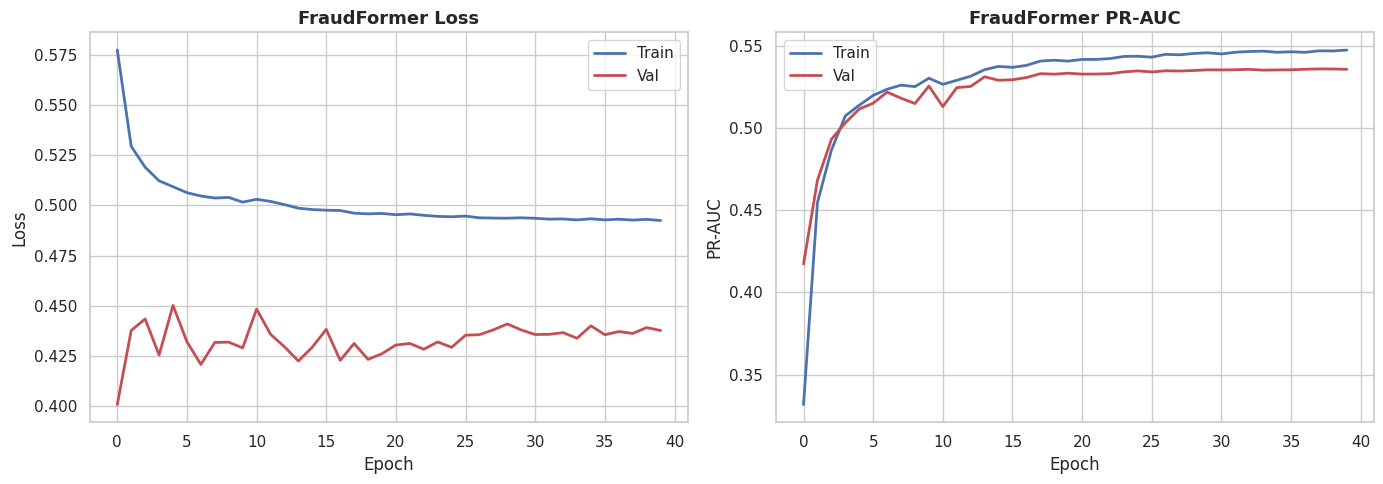

In [34]:
# Cell 5.4 — FraudFormer evaluation
y_val_prob_ff  = fraudformer.predict(X_val_ff, batch_size=8192, verbose=0).ravel()
y_test_prob_ff = fraudformer.predict(X_test_ff, batch_size=8192, verbose=0).ravel()

iso_ff = IsotonicRegression(out_of_bounds="clip")
iso_ff.fit(y_val_prob_ff, y_val)
y_val_prob_ff_cal  = iso_ff.predict(y_val_prob_ff)
y_test_prob_ff_cal = iso_ff.predict(y_test_prob_ff)

THR_FF, F1_FF = best_f1_threshold(y_val, y_val_prob_ff_cal)
print(f"FraudFormer val PR-AUC : {average_precision_score(y_val, y_val_prob_ff_cal):.4f}")
print(f"FraudFormer test PR-AUC: {average_precision_score(y_test, y_test_prob_ff_cal):.4f}")
print(f"Threshold: {THR_FF:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(hist_ff.history["loss"], label="Train", color="#4C72B0", linewidth=2)
axes[0].plot(hist_ff.history["val_loss"], label="Val", color="#C44E52", linewidth=2)
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].set_title("FraudFormer Loss"); axes[0].legend()

axes[1].plot(hist_ff.history["auc"], label="Train", color="#4C72B0", linewidth=2)
axes[1].plot(hist_ff.history["val_auc"], label="Val", color="#C44E52", linewidth=2)
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("PR-AUC")
axes[1].set_title("FraudFormer PR-AUC"); axes[1].legend()

plt.tight_layout(); plt.savefig(f"{FIG_DIR}/01_fraudformer_curves.png", dpi=150); plt.show()

In [35]:
# Cell 6.1 — AEGAN component layers

class AEGANEncoder(layers.Layer):
    def __init__(self, latent_dim, hidden=64, **kwargs):
        super().__init__(**kwargs)
        self.latent_dim = latent_dim; self.hidden = hidden
        self.net = tf.keras.Sequential([
            layers.Dense(hidden, activation="leaky_relu"),
            layers.Dense(hidden, activation="leaky_relu"),
            layers.Dense(latent_dim)])
    def call(self, x, training=False): return self.net(x, training=training)
    def get_config(self):
        config = super().get_config()
        config.update({"latent_dim": self.latent_dim, "hidden": self.hidden})
        return config

class AEGANDecoder(layers.Layer):
    def __init__(self, n_features, hidden=64, **kwargs):
        super().__init__(**kwargs)
        self.n_features = n_features; self.hidden = hidden
        self.net = tf.keras.Sequential([
            layers.Dense(hidden, activation="leaky_relu"),
            layers.Dense(hidden, activation="leaky_relu"),
            layers.Dense(n_features, activation="tanh")])
    def call(self, z, training=False): return self.net(z, training=training)
    def get_config(self):
        config = super().get_config()
        config.update({"n_features": self.n_features, "hidden": self.hidden})
        return config

class AEGANDiscriminator(layers.Layer):
    def __init__(self, hidden=64, **kwargs):
        super().__init__(**kwargs); self.hidden = hidden
        self.net = tf.keras.Sequential([
            layers.Dense(hidden, activation="leaky_relu"),
            layers.Dropout(0.2),
            layers.Dense(hidden // 2, activation="leaky_relu"),
            layers.Dense(1)])
    def call(self, x, training=False): return self.net(x, training=training)
    def get_config(self):
        config = super().get_config(); config.update({"hidden": self.hidden})
        return config

LATENT_DIM = 16
aegan_encoder = AEGANEncoder(LATENT_DIM)
aegan_decoder = AEGANDecoder(len(FEATURES))
aegan_disc    = AEGANDiscriminator()

opt_ae = optimizers.Adam(1e-3)
opt_d  = optimizers.Adam(2e-4)
opt_g  = optimizers.Adam(2e-4)
print("AEGAN layers created.")

AEGAN layers created.


In [36]:
# Cell 6.2 — Train AEGAN on fraud rows
fraud_train = X_train_ff[y_train == 1]
n_fraud = len(fraud_train)
print(f"Training AEGAN on {n_fraud:,} fraud rows")

BATCH_SIZE = 256
EPOCHS_AEGAN = 30

fraud_ds = tf.data.Dataset.from_tensor_slices(fraud_train) \
                          .shuffle(5000, seed=SEED).batch(BATCH_SIZE).repeat()

def aegan_train_step(real_batch):
    bs = tf.shape(real_batch)[0]
    # Reconstruction
    with tf.GradientTape() as ae_tape:
        z = aegan_encoder(real_batch, training=True)
        recon = aegan_decoder(z, training=True)
        recon_loss = tf.reduce_mean(tf.square(real_batch - recon))
    ae_grads = ae_tape.gradient(recon_loss,
                                aegan_encoder.trainable_variables +
                                aegan_decoder.trainable_variables)
    opt_ae.apply_gradients(zip(ae_grads,
                                aegan_encoder.trainable_variables +
                                aegan_decoder.trainable_variables))
    # Discriminator
    z_lat = tf.random.normal((bs, LATENT_DIM))
    with tf.GradientTape() as d_tape:
        fake = aegan_decoder(z_lat, training=True)
        real_score = aegan_disc(real_batch, training=True)
        fake_score = aegan_disc(fake, training=True)
        d_loss = tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(
                     tf.ones_like(real_score), real_score)) + \
                 tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(
                     tf.zeros_like(fake_score), fake_score))
    d_grads = d_tape.gradient(d_loss, aegan_disc.trainable_variables)
    opt_d.apply_gradients(zip(d_grads, aegan_disc.trainable_variables))
    # Generator
    z_lat = tf.random.normal((bs, LATENT_DIM))
    with tf.GradientTape() as g_tape:
        fake = aegan_decoder(z_lat, training=True)
        fake_score = aegan_disc(fake, training=True)
        g_adv = tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(
                    tf.ones_like(fake_score), fake_score))
        z = aegan_encoder(real_batch, training=True)
        recon = aegan_decoder(z, training=True)
        g_rec = tf.reduce_mean(tf.square(real_batch - recon))
        g_loss = 0.1 * g_adv + 1.0 * g_rec
    g_grads = g_tape.gradient(g_loss,
                              aegan_encoder.trainable_variables +
                              aegan_decoder.trainable_variables)
    opt_g.apply_gradients(zip(g_grads,
                              aegan_encoder.trainable_variables +
                              aegan_decoder.trainable_variables))
    return recon_loss, d_loss, g_loss

batch_iter = iter(fraud_ds)
t0 = time.time()
recon_hist, d_hist, g_hist = [], [], []
for epoch in range(EPOCHS_AEGAN):
    er, ed, eg, nb = 0.0, 0.0, 0.0, 0
    for _ in range(n_fraud // BATCH_SIZE):
        r, d, g = aegan_train_step(next(batch_iter))
        er += float(r); ed += float(d); eg += float(g); nb += 1
    recon_hist.append(er/nb); d_hist.append(ed/nb); g_hist.append(eg/nb)
    if (epoch+1) % 5 == 0:
        print(f"Epoch {epoch+1:2d}/{EPOCHS_AEGAN} | Recon: {recon_hist[-1]:.4f} D: {d_hist[-1]:.4f} G: {g_hist[-1]:.4f}")

aegan_time = time.time() - t0
print(f"\nAEGAN trained in {aegan_time/60:.2f} min")

Training AEGAN on 17,683 fraud rows
Epoch  5/30 | Recon: 0.4682 D: 0.9167 G: 0.5714
Epoch 10/30 | Recon: 0.4652 D: 0.8442 G: 0.5721
Epoch 15/30 | Recon: 0.4588 D: 0.7234 G: 0.5987
Epoch 20/30 | Recon: 0.4593 D: 0.7041 G: 0.6258
Epoch 25/30 | Recon: 0.4619 D: 0.7278 G: 0.6227
Epoch 30/30 | Recon: 0.4571 D: 0.7177 G: 0.6233

AEGAN trained in 8.34 min


Generated: (25000, 14)


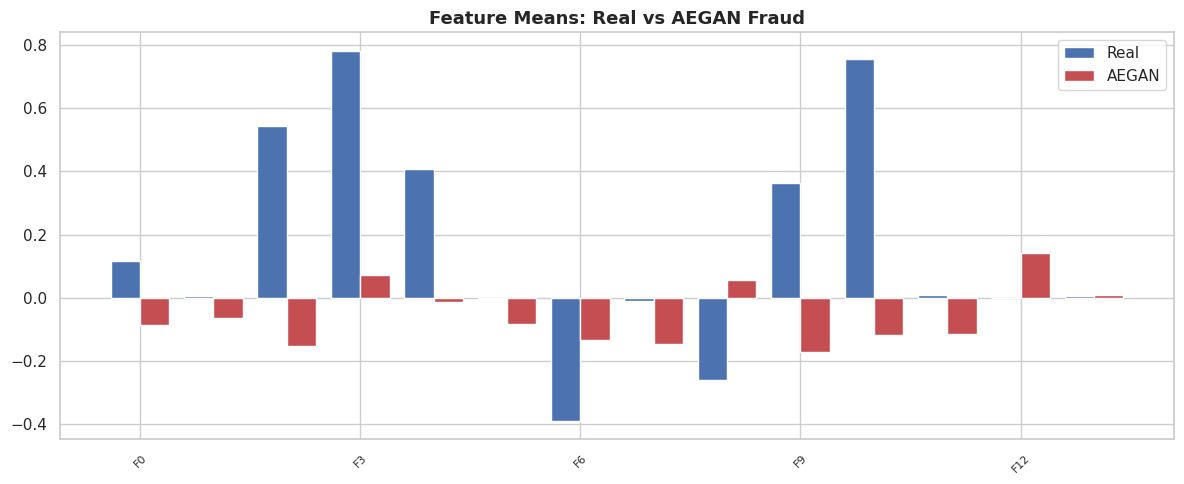

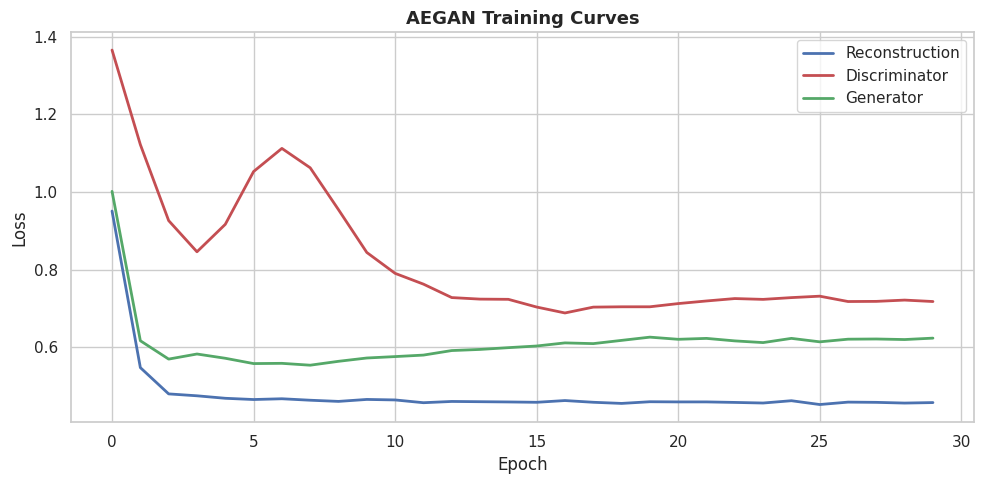

In [37]:
# Cell 6.3 — Generate synthetic fraud
N_SYNTH = 25_000
z_synth = tf.random.normal((N_SYNTH, LATENT_DIM), seed=SEED)
synth_fraud = aegan_decoder(z_synth, training=False).numpy()

print(f"Generated: {synth_fraud.shape}")

real_mean = fraud_train.mean(axis=0)
synth_mean = synth_fraud.mean(axis=0)

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(FEATURES))
ax.bar(x - 0.2, real_mean, 0.4, label="Real", color="#4C72B0")
ax.bar(x + 0.2, synth_mean, 0.4, label="AEGAN", color="#C44E52")
ax.set_xticks(x[::3]); ax.set_xticklabels([f"F{i}" for i in x[::3]], rotation=45, fontsize=8)
ax.set_title("Feature Means: Real vs AEGAN Fraud"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/02_aegan_distribution.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(recon_hist, label="Reconstruction", color="#4C72B0", linewidth=2)
ax.plot(d_hist, label="Discriminator", color="#C44E52", linewidth=2)
ax.plot(g_hist, label="Generator", color="#55A868", linewidth=2)
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
ax.set_title("AEGAN Training Curves"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/03_aegan_curves.png", dpi=150); plt.show()

In [38]:
# Cell 7.1 — AEGAN as data augmentation
synth_fraud_raw = scaler_ff.inverse_transform(synth_fraud)
synth_df = pd.DataFrame(synth_fraud_raw, columns=FEATURES)

X_train_aug = pd.concat([X_train.reset_index(drop=True), synth_df], ignore_index=True)
y_train_aug = np.concatenate([y_train, np.ones(N_SYNTH, dtype=np.float32)])

print(f"Original : {len(X_train):,} | fraud={int(y_train.sum()):,}")
print(f"Augmented: {len(X_train_aug):,} | fraud={int(y_train_aug.sum()):,}")

dtrain_aug = lgb.Dataset(X_train_aug, label=y_train_aug)
dval_aug = lgb.Dataset(X_val, label=y_val, reference=dtrain_aug)
lgb_aug = lgb.train(lgb_params, dtrain_aug, num_boost_round=2000,
                    valid_sets=[dval_aug], valid_names=["val"],
                    callbacks=[lgb.early_stopping(50, verbose=False)])

y_val_prob_lgb_aug  = lgb_aug.predict(X_val, num_iteration=lgb_aug.best_iteration)
y_test_prob_lgb_aug = lgb_aug.predict(X_test, num_iteration=lgb_aug.best_iteration)

iso_aug = IsotonicRegression(out_of_bounds="clip")
iso_aug.fit(y_val_prob_lgb_aug, y_val)
y_val_prob_lgb_aug_cal  = iso_aug.predict(y_val_prob_lgb_aug)
y_test_prob_lgb_aug_cal = iso_aug.predict(y_test_prob_lgb_aug)
THR_LGB_AUG, F1_LGB_AUG = best_f1_threshold(y_val, y_val_prob_lgb_aug_cal)

print(f"\nLightGBM + AEGAN augmentation:")
print(f"  Val PR-AUC : {average_precision_score(y_val, y_val_prob_lgb_aug_cal):.4f}")
print(f"  Test PR-AUC: {average_precision_score(y_test, y_test_prob_lgb_aug_cal):.4f}")

Original : 351,615 | fraud=17,683
Augmented: 376,615 | fraud=42,683

LightGBM + AEGAN augmentation:
  Val PR-AUC : 0.5206
  Test PR-AUC: 0.5268


In [39]:
# Cell 8.1 — Final comparison
def evaluate_at(y_true, y_prob, thr, name):
    pred = (y_prob >= thr).astype(int)
    return {"model": name, "threshold": round(thr, 4),
            "roc_auc": round(roc_auc_score(y_true, y_prob), 4),
            "pr_auc": round(average_precision_score(y_true, y_prob), 4),
            "precision": round(precision_score(y_true, pred, zero_division=0), 4),
            "recall": round(recall_score(y_true, pred, zero_division=0), 4),
            "f1": round(f1_score(y_true, pred, zero_division=0), 4)}

comparison = pd.DataFrame([
    evaluate_at(y_test, y_test_prob_lgb_cal,     THR_LGB,     "LightGBM (baseline)"),
    evaluate_at(y_test, y_test_prob_lgb_aug_cal, THR_LGB_AUG, "LightGBM + AEGAN"),
    evaluate_at(y_test, y_test_prob_ff_cal,      THR_FF,      "FraudFormer (custom)"),
]).sort_values("pr_auc", ascending=False)

print("=" * 95)
print("FINAL COMPARISON — TEST SET")
print("=" * 95)
print(comparison.to_string(index=False))
print("=" * 95)
comparison.to_csv(f"{MODEL_DIR}/final_comparison.csv", index=False)

FINAL COMPARISON — TEST SET
               model  threshold  roc_auc  pr_auc  precision  recall     f1
FraudFormer (custom)     0.3521   0.7692  0.5330     0.8511  0.4473 0.5864
    LightGBM + AEGAN     0.3000   0.7652  0.5268     0.8411  0.4357 0.5741
 LightGBM (baseline)     0.3286   0.7661  0.5237     0.7985  0.4392 0.5667


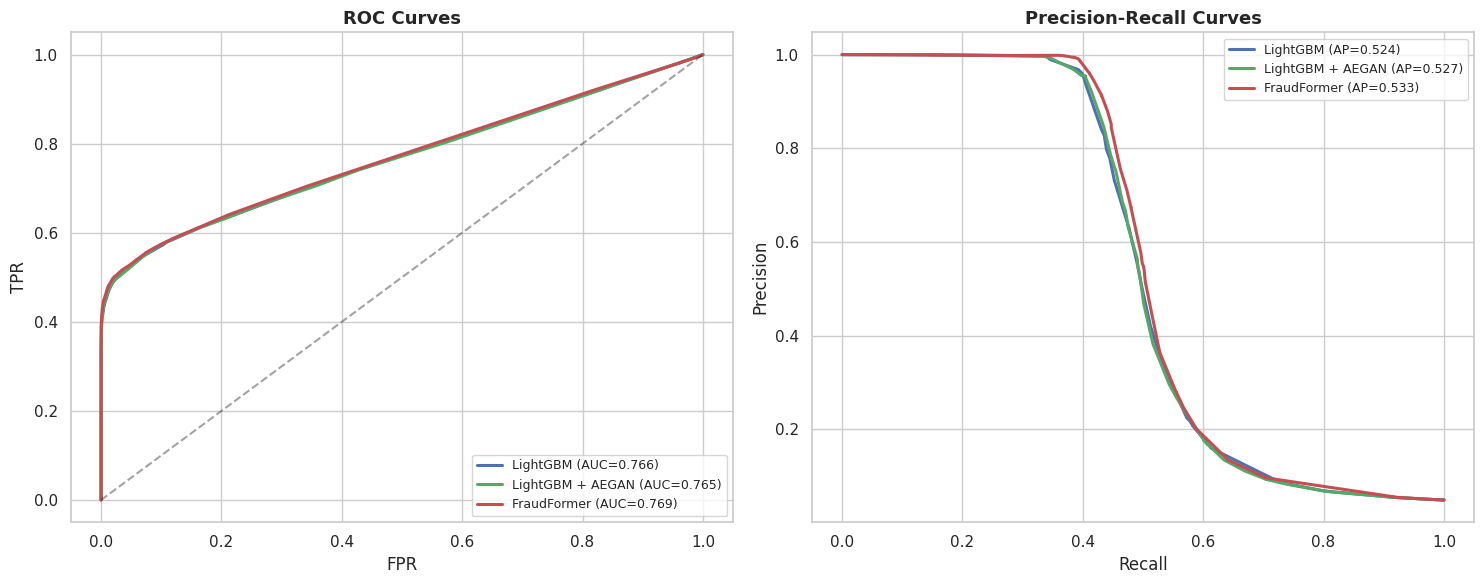

In [40]:
# Cell 8.2 — ROC and PR curves
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
curves = [
    ("LightGBM",         y_test, y_test_prob_lgb_cal,     "#4C72B0"),
    ("LightGBM + AEGAN", y_test, y_test_prob_lgb_aug_cal, "#55A868"),
    ("FraudFormer",      y_test, y_test_prob_ff_cal,      "#C44E52"),
]
for name, y_t, y_p, color in curves:
    fpr, tpr, _ = roc_curve(y_t, y_p)
    axes[0].plot(fpr, tpr, color=color, linewidth=2.2,
                 label=f"{name} (AUC={roc_auc_score(y_t, y_p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR")
axes[0].set_title("ROC Curves"); axes[0].legend(loc="lower right", fontsize=9)

for name, y_t, y_p, color in curves:
    p, r, _ = precision_recall_curve(y_t, y_p)
    axes[1].plot(r, p, color=color, linewidth=2.2,
                 label=f"{name} (AP={average_precision_score(y_t, y_p):.3f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curves"); axes[1].legend(loc="upper right", fontsize=9)

plt.tight_layout(); plt.savefig(f"{FIG_DIR}/04_all_models.png", dpi=150); plt.show()

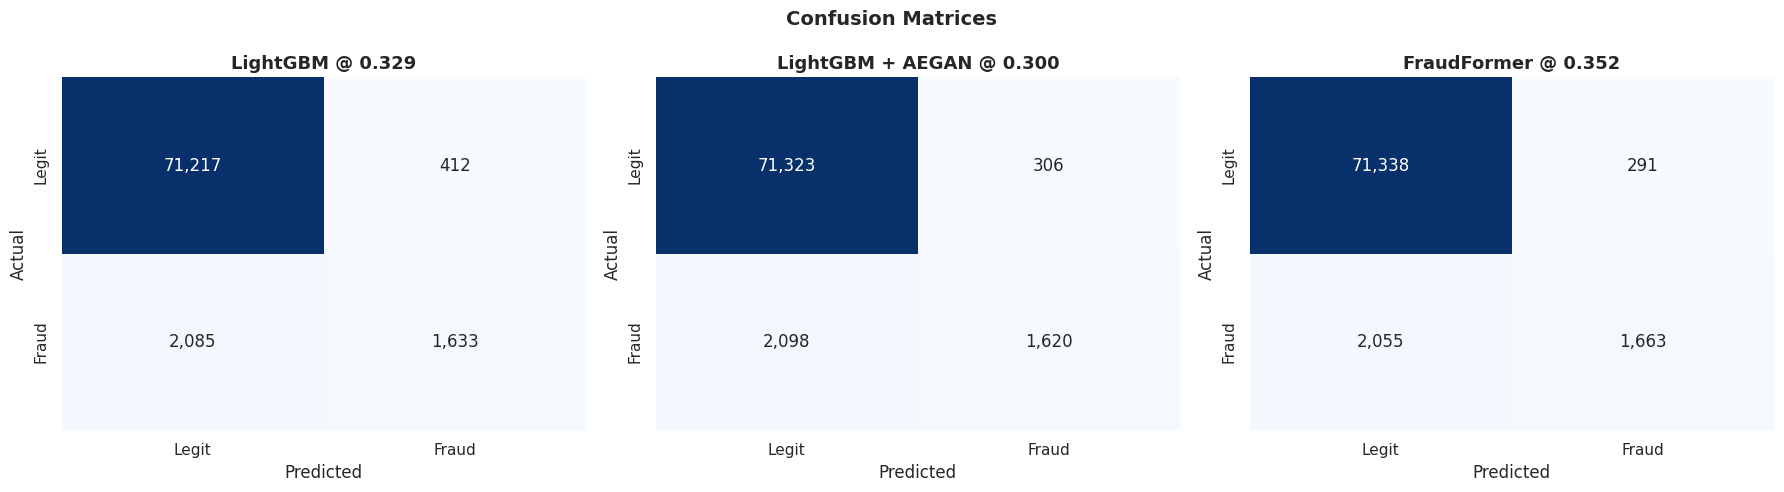

In [41]:
# Cell 8.3 — Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name, y_prob, thr in [
    (axes[0], "LightGBM",         y_test_prob_lgb_cal,     THR_LGB),
    (axes[1], "LightGBM + AEGAN", y_test_prob_lgb_aug_cal, THR_LGB_AUG),
    (axes[2], "FraudFormer",      y_test_prob_ff_cal,      THR_FF),
]:
    pred = (y_prob >= thr).astype(int)
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", ax=ax,
                xticklabels=["Legit", "Fraud"], yticklabels=["Legit", "Fraud"],
                cbar=False)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(f"{name} @ {thr:.3f}")
plt.suptitle("Confusion Matrices", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/05_confusions.png", dpi=150); plt.show()

Attention shape: (2000, 4, 14, 14)
Row sums (should be ~1): [0.99999875 0.9999987  0.9999998  0.9999993  0.9999991 ]


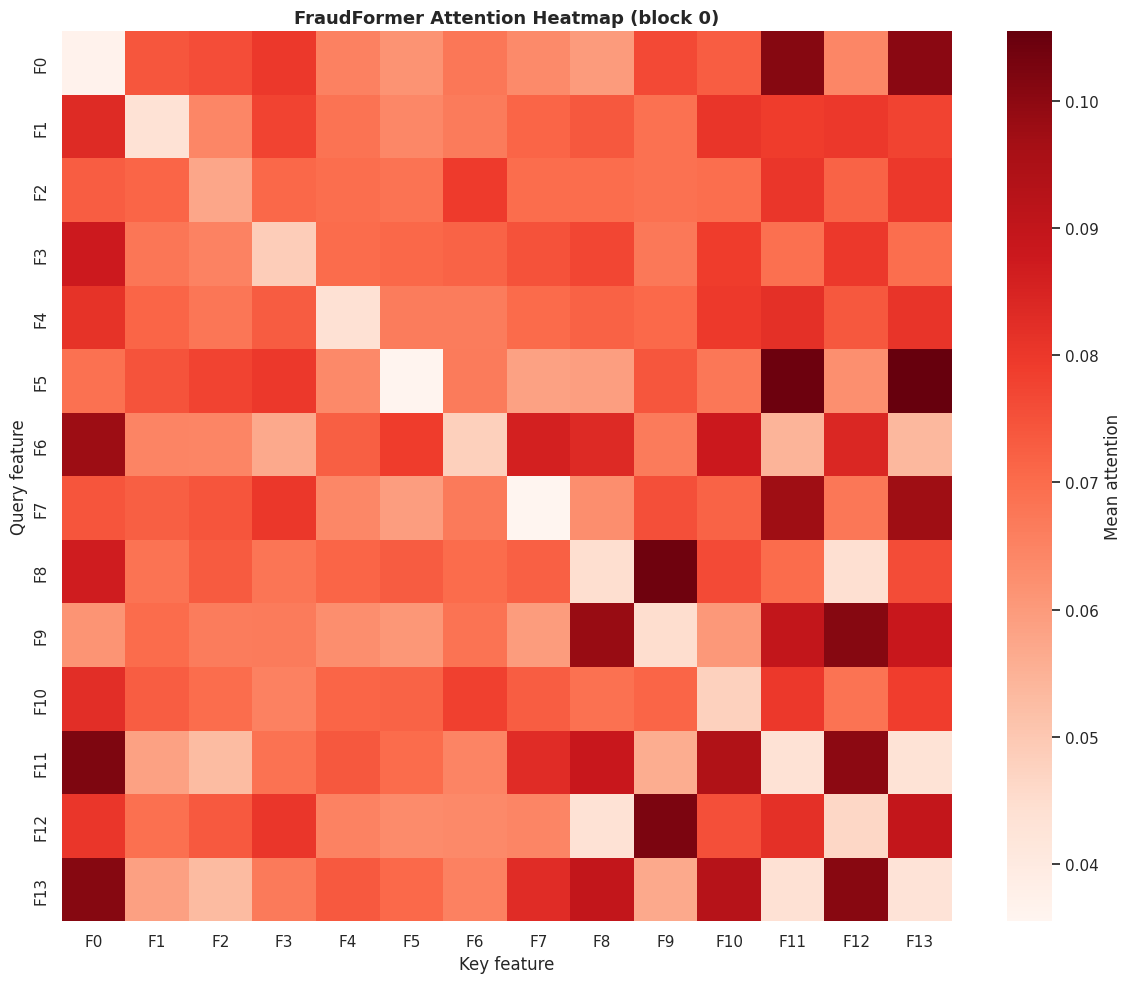


Top 10 learned feature interactions:
  avg_amount_30d               -> weekday                        0.1055
  avg_amount_30d               -> month                          0.1046
  hour_of_day                  -> is_night                       0.1042
  hour                         -> is_night                       0.1023
  month                        -> amount                         0.1021
  is_night                     -> hour                           0.1010
  amount                       -> month                          0.1010
  weekday                      -> amount                         0.1009
  weekday                      -> hour                           0.1008
  amount                       -> weekday                        0.1005


In [42]:
# Cell 8.4 — FraudFormer attention extraction
sample = X_test_ff[:2000].astype(np.float32)
_, all_attn = fraudformer(sample, training=False, return_attention=True)
mean_attn = all_attn[0].numpy().mean(axis=(0, 1))

print(f"Attention shape: {all_attn[0].shape}")
print(f"Row sums (should be ~1): {mean_attn.sum(axis=1)[:5]}")

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(mean_attn, cmap="Reds", ax=ax,
            xticklabels=[f"F{i}" for i in range(len(FEATURES))],
            yticklabels=[f"F{i}" for i in range(len(FEATURES))],
            cbar_kws={"label": "Mean attention"})
ax.set_title("FraudFormer Attention Heatmap (block 0)")
ax.set_xlabel("Key feature"); ax.set_ylabel("Query feature")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/06_attention.png", dpi=150); plt.show()

mask = ~np.eye(len(FEATURES), dtype=bool)
pairs = [(FEATURES[i], FEATURES[j], float(mean_attn[i, j]))
         for i in range(len(FEATURES)) for j in range(len(FEATURES)) if mask[i, j]]
pairs.sort(key=lambda x: -x[2])
print("\nTop 10 learned feature interactions:")
for src, tgt, w in pairs[:10]:
    print(f"  {src:28s} -> {tgt:28s} {w:>8.4f}")

In [43]:
# Cell 8.5 — Save artifacts
fraudformer.save(f"{MODEL_DIR}/fraudformer.keras")
from tensorflow.keras import layers as L

# Wrap AEGAN layers as models
enc_in = L.Input(shape=(len(FEATURES),), name="features")
enc_out = aegan_encoder(enc_in)
Model(enc_in, enc_out, name="AEGANEncoder").save(f"{MODEL_DIR}/aegan_encoder.keras")

dec_in = L.Input(shape=(LATENT_DIM,), name="latent")
dec_out = aegan_decoder(dec_in)
Model(dec_in, dec_out, name="AEGANDecoder").save(f"{MODEL_DIR}/aegan_decoder.keras")

disc_in = L.Input(shape=(len(FEATURES),), name="features")
disc_out = aegan_disc(disc_in)
Model(disc_in, disc_out, name="AEGANDiscriminator").save(f"{MODEL_DIR}/aegan_discriminator.keras")

joblib.dump(scaler_ff, f"{MODEL_DIR}/scaler_ff.pkl")
joblib.dump(iso, f"{MODEL_DIR}/iso_lgb.pkl")
joblib.dump(iso_ff, f"{MODEL_DIR}/iso_ff.pkl")
joblib.dump(iso_aug, f"{MODEL_DIR}/iso_lgb_aug.pkl")
joblib.dump(FEATURES, f"{MODEL_DIR}/features.pkl")
lgb_model.save_model(f"{MODEL_DIR}/lgbm_baseline.txt")
lgb_aug.save_model(f"{MODEL_DIR}/lgbm_augmented.txt")

meta = {
    "n_features": len(FEATURES),
    "n_train": len(X_train), "n_val": len(X_val), "n_test": len(X_test),
    "thresholds": {"lgb": THR_LGB, "lgb_aug": THR_LGB_AUG, "ff": THR_FF},
    "best_models": comparison.to_dict(orient="records"),
    "aegan_latent_dim": int(LATENT_DIM),
    "aegan_synthetic_count": int(N_SYNTH),
}
with open(f"{MODEL_DIR}/metadata.json", "w") as f:
    json.dump(meta, f, indent=2, default=float)

print("Saved artifacts:")
for f in sorted(os.listdir(MODEL_DIR)):
    size = os.path.getsize(os.path.join(MODEL_DIR, f)) / 1024
    print(f"  {f:35s} {size:>8.1f} KB")

Saved artifacts:
  aegan_decoder.keras                     46.7 KB
  aegan_discriminator.keras               36.5 KB
  aegan_encoder.keras                     46.7 KB
  features.pkl                             0.2 KB
  final_comparison.csv                     0.2 KB
  fraudformer.keras                     2171.1 KB
  iso_ff.pkl                               1.1 KB
  iso_lgb.pkl                              1.8 KB
  iso_lgb_aug.pkl                          1.9 KB
  lgbm_augmented.txt                     361.6 KB
  lgbm_baseline.txt                      360.5 KB
  metadata.json                            0.8 KB
  scaler_ff.pkl                            1.4 KB


In [44]:
# Cell 8.6 — Final summary
print("=" * 95)
print("FRAUDGUARD v4.0 — FINAL SUMMARY")
print("=" * 95)
print(f"Dataset rows        : {len(df):,}")
print(f"Fraud rate          : {df['fraud_label'].mean()*100:.2f}%")
print(f"Features            : {len(FEATURES)}")
print(f"Train/Val/Test      : {len(X_train):,} / {len(X_val):,} / {len(X_test):,}")
print()
print("CUSTOM MODEL TRAINING TIMES")
print(f"  FraudFormer (transformer) : {ff_time/60:.2f} min")
print(f"  AEGAN (adversarial)       : {aegan_time/60:.2f} min")
print()
print("FINAL TEST METRICS")
print("-" * 95)
print(comparison.to_string(index=False))
print("=" * 95)
best = comparison.iloc[0]
print(f"\nBEST MODEL: {best['model']}")
print(f"  ROC-AUC : {best['roc_auc']:.4f}")
print(f"  PR-AUC  : {best['pr_auc']:.4f}")
print(f"  F1      : {best['f1']:.4f}")

FRAUDGUARD v4.0 — FINAL SUMMARY
Dataset rows        : 502,308
Fraud rate          : 4.99%
Features            : 14
Train/Val/Test      : 351,615 / 75,346 / 75,347

CUSTOM MODEL TRAINING TIMES
  FraudFormer (transformer) : 5.90 min
  AEGAN (adversarial)       : 8.34 min

FINAL TEST METRICS
-----------------------------------------------------------------------------------------------
               model  threshold  roc_auc  pr_auc  precision  recall     f1
FraudFormer (custom)     0.3521   0.7692  0.5330     0.8511  0.4473 0.5864
    LightGBM + AEGAN     0.3000   0.7652  0.5268     0.8411  0.4357 0.5741
 LightGBM (baseline)     0.3286   0.7661  0.5237     0.7985  0.4392 0.5667

BEST MODEL: FraudFormer (custom)
  ROC-AUC : 0.7692
  PR-AUC  : 0.5330
  F1      : 0.5864


In [45]:
# Cell 9.2 — Package everything into a downloadable zip
import os, zipfile, shutil, json
from datetime import datetime

timestamp = datetime.now().strftime("%Y%m%d_%H%M")
STAGING = f"/kaggle/working/_package_{timestamp}"
ZIP_PATH = f"/kaggle/working/fraudguard_v4_{timestamp}.zip"

os.makedirs(STAGING, exist_ok=True)

# ---------- 1. Datasets ----------
datasets_dir = os.path.join(STAGING, "01_datasets")
os.makedirs(datasets_dir, exist_ok=True)

for src, dst in [
    (CLEAN_PATH, "cleaned_fraud_data.csv"),
    (MESSY_PATH, "messy_fraud_data_raw.csv"),
]:
    if os.path.exists(src):
        shutil.copy2(src, os.path.join(datasets_dir, dst))
        print(f"Copied dataset: {dst}")

# ---------- 2. Models ----------
models_dir = os.path.join(STAGING, "02_models")
os.makedirs(models_dir, exist_ok=True)

if os.path.exists(MODEL_DIR):
    shutil.copytree(MODEL_DIR, os.path.join(models_dir, "models_v4"))
    print(f"Copied model directory: {os.path.basename(MODEL_DIR)}")

# ---------- 3. Figures ----------
figures_dir = os.path.join(STAGING, "03_figures")
os.makedirs(figures_dir, exist_ok=True)

if os.path.exists(FIG_DIR):
    shutil.copytree(FIG_DIR, os.path.join(figures_dir, "figures_v4"))
    print(f"Copied figures: {os.path.basename(FIG_DIR)}")

# ---------- 4. Results CSV ----------
reports_dir = os.path.join(STAGING, "04_reports")
os.makedirs(reports_dir, exist_ok=True)

comparison_path = os.path.join(MODEL_DIR, "final_comparison.csv")
if os.path.exists(comparison_path):
    shutil.copy2(comparison_path, os.path.join(reports_dir, "final_comparison.csv"))
    print("Copied final_comparison.csv")

metadata_path = os.path.join(MODEL_DIR, "metadata.json")
if os.path.exists(metadata_path):
    shutil.copy2(metadata_path, os.path.join(reports_dir, "metadata.json"))
    print("Copied metadata.json")

# ---------- 5. README ----------
readme_text = f"""FRAUDGUARD v4.0
Generated: {timestamp}

CONTENTS
========

01_datasets/
    cleaned_fraud_data.csv         Final cleaned dataset (502,308 rows)
    messy_fraud_data_raw.csv       Raw messy dataset before cleaning

02_models/models_v4/
    fraudformer.keras              Custom transformer model (BEST MODEL)
    aegan_encoder.keras            AEGAN encoder
    aegan_decoder.keras            AEGAN decoder (fraud generator)
    aegan_discriminator.keras      AEGAN discriminator
    lgbm_baseline.txt              LightGBM baseline (text)
    lgbm_augmented.txt             LightGBM + AEGAN augmentation (text)
    scaler_ff.pkl                  StandardScaler for neural inputs
    iso_lgb.pkl                    Isotonic calibrator (LightGBM)
    iso_ff.pkl                     Isotonic calibrator (FraudFormer)
    iso_lgb_aug.pkl                Isotonic calibrator (LightGBM+AEGAN)
    features.pkl                   Ordered feature list (14 features)
    metadata.json                  Thresholds and hyperparameters
    final_comparison.csv           Test set metrics for all models

03_figures/figures_v4/
    01_fraudformer_curves.png      Loss and PR-AUC curves
    02_aegan_distribution.png      Real vs synthetic fraud distribution
    03_aegan_curves.png            AEGAN training curves
    04_all_models.png              ROC and PR curves (all models)
    05_confusions.png              Confusion matrices
    06_attention.png               FraudFormer attention heatmap

04_reports/
    final_comparison.csv           Full test metrics table
    metadata.json                  Model configuration

FINAL RESULTS (Test Set)
========================
Model                     ROC-AUC   PR-AUC    F1
FraudFormer (custom)      0.7692    0.5330    0.5864   <-- BEST
LightGBM + AEGAN          0.7652    0.5268    0.5741
LightGBM (baseline)       0.7661    0.5237    0.5667

DATASET
=======
Rows           : 502,308
Fraud rate     : 4.99%
Features used  : 14
Time split     : 70/15/15 (time-aware)

PIPELINE
========
1. Leak-free synthetic generation (single base distribution + interaction drift)
2. Cleaning (25+ messiness categories handled)
3. Time-aware split (no shuffling)
4. Feature engineering (14 raw + derived features)
5. LightGBM baseline (scale_pos_weight)
6. AEGAN (custom adversarial autoencoder)
7. FraudFormer (custom self-attention transformer)
8. Isotonic calibration
9. F1-optimal threshold selection
10. Test set evaluation

REPRODUCIBILITY
===============
Random seed     : 42
Python          : 3.10+
TensorFlow      : 2.x
LightGBM        : 4.x

USAGE
=====
# Load and predict with FraudFormer
from tensorflow.keras.models import load_model
import joblib
import numpy as np

model = load_model('02_models/models_v4/fraudformer.keras')
scaler = joblib.load('02_models/models_v4/scaler_ff.pkl')
features = joblib.load('02_models/models_v4/features.pkl')
meta = json.load(open('02_models/models_v4/metadata.json'))

def predict(transaction_dict):
    x = np.array([[transaction_dict[f] for f in features]])
    x = scaler.transform(x).clip(-8, 8)
    prob = model.predict(x, verbose=0)[0, 0]
    return {{
        'fraud_probability': float(prob),
        'is_fraud': bool(prob >= meta['thresholds']['ff']),
        'threshold': meta['thresholds']['ff'],
    }}

# Load and predict with LightGBM + AEGAN
import lightgbm as lgb
lgb_model = lgb.Booster(model_file='02_models/models_v4/lgbm_augmented.txt')
"""

with open(os.path.join(STAGING, "README.txt"), "w") as f:
    f.write(readme_text)
print("Wrote README.txt")

# ---------- 6. Create zip ----------
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED, compresslevel=6) as zf:
    for root, _, files in os.walk(STAGING):
        for file in files:
            full_path = os.path.join(root, file)
            arcname = os.path.relpath(full_path, STAGING)
            zf.write(full_path, arcname)

shutil.rmtree(STAGING, ignore_errors=True)

size_mb = os.path.getsize(ZIP_PATH) / 1e6
print(f"\n{'=' * 70}")
print(f"ZIP CREATED: {ZIP_PATH}")
print(f"Size       : {size_mb:.2f} MB")
print(f"{'=' * 70}")

Copied dataset: cleaned_fraud_data.csv
Copied dataset: messy_fraud_data_raw.csv
Copied model directory: models_v4
Copied figures: figures_v4
Copied final_comparison.csv
Copied metadata.json
Wrote README.txt

ZIP CREATED: /kaggle/working/fraudguard_v4_20261017_1520.zip
Size       : 51.55 MB
